# КИВО: очистка данных

**Это блокнот очистки данных.** Здесь исходный файл `data.sav` превращается в очищенный набор данных. Гипотезы здесь не проверяются — анализ выполняется в отдельном блокноте **`analysis.ipynb`**.

**Порядок работы**
1. `cleaning.ipynb` (этот блокнот) — читает `data.sav`, сохраняет `data_clean.pkl` и `data_imputed.pkl`. Полный прогон — около 25 минут.
2. `analysis.ipynb` — загружает очищенные данные и проверяет гипотезы из `hypotheses.md`.

Описание методов для статьи — `methods.md`.

**Принципы очистки**
- Исходные столбцы не меняются: для каждой переменной создаются статус ответа (`*_st`), аналитическая переменная и флаг качества (`q_*`, `qsrc_*`).
- Из рабочего массива исключаются только записи без единого ответа.
- «Затрудняюсь», отказ и «другое» — заполненные ответы, а не пропуски; пустая ячейка не считается отказом.
- Значения, ошибочность которых не доказана, не удаляются, а помечаются флагами.

**Содержание**
1. Библиотеки и настройки
2. Загрузка и первичный обзор
3. Рабочий массив
4. Частично заполненные анкеты 4-й волны
5. Повторяющиеся записи
6. Составные переменные
7. Порядок вопросов и точка прерывания
8. Применимость вопросов и специальные коды
9. Статусы ответов
10. Аналитические переменные
11. Специальные ответы по группам
12. Механизм пропусков
13. Выбывание между волнами
14. Аналитические выборки
15. Восстановление пропусков (MICE)
16. Флаги качества
17. Протокол очистки
18. Сохранение

## 1. Библиотеки и настройки

Все библиотеки подключаются здесь. `SEED` фиксирует генератор случайных чисел: перестановочные тесты и восстановление пропусков при каждом запуске дают одинаковый результат.

In [1]:
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadstat
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import optimize, stats
from scipy.special import softmax
from sklearn.metrics import roc_auc_score
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid', context='notebook')

SEED = 2026
rng = np.random.default_rng(SEED)

## 2. Загрузка и первичный обзор

Читаем исходный файл. `df` — исходные данные, дальше они не меняются; `meta` — формулировки вопросов и метки вариантов ответа.

In [2]:
df, meta = pyreadstat.read_sav('data.sav')
print(f'Строк: {df.shape[0]}, столбцов: {df.shape[1]}')

Строк: 5831, столбцов: 82


**Вывод.** 5 831 строка и 82 переменные.

Обзор переменных: формулировка вопроса, тип и число заполненных ячеек.

In [3]:
overview = pd.DataFrame({
    'вопрос': [meta.column_names_to_labels.get(c) for c in df.columns],
    'тип': df.dtypes.astype(str).values,
    'заполнено': df.notna().sum().values,
    'пусто': df.isna().sum().values,
}, index=df.columns)
overview['пусто, %'] = (overview['пусто'] / len(df) * 100).round(1)
overview

,вопрос,тип,заполнено,пусто,"пусто, %"
bigmajor,Укрупненное направление подготовки,float64,4900,931,16.0
funding,Вы обучаетесь:,float64,4726,1105,19.0
sex,Осталось несколько вопросов о вас и вашей семьеВаш пол:,float64,4899,932,16.0
ses1,Как бы вы оценили материальное положение вашей семьи (или других родственник...,float64,3988,1843,31.6
wave3,Участвовали в 3 волне,str,5831,0,0.0
edu3_3w,"Представьте, если бы вам вновь пришлось поступать в вуз, то что бы вы выбрали?",float64,1223,4608,79.0
satisfaction_3w,Насколько вы удовлетворены обучением в вашем университете?,float64,1166,4665,80.0
dropout1_3w,"Задумывались ли вы в течение обучения о том, чтобы отчислиться из университета?",str,5831,0,0.0
dropout2_3w_1_1,Разочаровался(-лась) в университете,float64,1236,4595,78.8
dropout2_3w_1_2,Разочаровался(-лась) в направлении подготовки,float64,1236,4595,78.8


**Вывод.** В каждой переменной много пустых ячеек: выгрузка содержит строки всех, кто открывал анкету, а не только ответивших. Поэтому сначала нужно отделить записи с ответами (раздел 3).

Создаём рабочую копию `d`. Три кодированных вопроса (`wave3`, `dropout1_3w`, `mark_3w`) выгружены строками — переводим их в числа; пустые строки в текстовых полях считаем пропусками. Сами значения не меняются.

In [4]:
def value_labels(var):
    '''Метки значений переменной из файла .sav.'''
    return meta.variable_value_labels.get(var, {})


# Три кодированных вопроса выгружены строками; пустые строки во всех текстовых полях — пропуски
d = df.copy()
text_cols = [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])]
d[text_cols] = d[text_cols].replace(r'^\s*$', np.nan, regex=True)
for col in ['wave3', 'dropout1_3w', 'mark_3w']:
    d[col] = pd.to_numeric(d[col], errors='coerce')

pd.crosstab(d['wave3'].eq(1).rename('wave3 = 1'), d['wave4'].eq(1).rename('wave4 = 1'), margins=True)

wave4 = 1,False,True,All
wave3 = 1,,,
False,3810,785,4595
True,514,722,1236
All,4324,1507,5831


**Вывод.** Признак участия `wave3` = 1 стоит у 1 236 строк, `wave4` = 1 — у 1 507. Ниже проверяем, совпадает ли он с реальным наличием ответов.

## 3. Рабочий массив

Из рабочего массива исключаются записи без единого ответа на исследуемые вопросы 3-й и 4-й волн. Ответами **не считаются**:
- фоновые характеристики `sex`, `bigmajor`, `funding`, `ses1` и признаки `wave3`, `wave4`;
- служебные поля: текстовые сводки `hours_3w`, `intern5_4w`, `dropout2_4w`;
- галочки причин отчисления, если не отмечено ни одной;
- распределение времени `hours_3w_1–6`, если все доли равны 0.

Участие в волне определяется по наличию ответов этой волны.

Отмечаем, есть ли у записи хотя бы один ответ в каждой волне.

In [5]:
BACKGROUND = ['bigmajor', 'funding', 'sex', 'ses1', 'wave3', 'wave4']
REASONS_3W = [f'dropout2_3w_1_{i}' for i in range(1, 8)]
REASONS_4W = [f'dropout2_4w_{i}' for i in range(1, 8)]
ALLOC_3W = [f'hours_3w_{i}' for i in range(1, 7)]
SERVICE = ['hours_3w', 'intern5_4w', 'dropout2_4w'] + REASONS_3W + ALLOC_3W

first_4w = df.columns.get_loc('edu3_4w')
Q3 = [c for c in df.columns[:first_4w] if c not in BACKGROUND + SERVICE]
Q4 = [c for c in df.columns[first_4w:] if c not in BACKGROUND + SERVICE + REASONS_4W]


def has_any_answer(questions, checkboxes=(), allocation=()):
    '''Есть ли в строке хотя бы один ответ на исследуемые вопросы.'''
    answered = d[questions].notna().any(axis=1)
    if checkboxes:
        answered |= d[list(checkboxes)].fillna(0).sum(axis=1) > 0
    if allocation:
        answered |= d[list(allocation)].fillna(0).sum(axis=1) > 0
    return answered


d['in_w3'] = has_any_answer(Q3, REASONS_3W, ALLOC_3W)
d['in_w4'] = has_any_answer(Q4, REASONS_4W)
d['in_study'] = d['in_w3'] | d['in_w4']
d['wave_flag_conflict'] = (d['wave3'].eq(1) != d['in_w3']) | (d['wave4'].eq(1) != d['in_w4'])

print(f'Исключено записей без ответов: {(~d["in_study"]).sum()}; рабочий массив: {d["in_study"].sum()}')
pd.crosstab(d['in_w3'].rename('ответы 3-й волны'), d['in_w4'].rename('ответы 4-й волны'), margins=True)

Исключено записей без ответов: 3809; рабочий массив: 2022


ответы 4-й волны,False,True,All
ответы 3-й волны,,,
False,3809,798,4607
True,509,715,1224
All,4318,1513,5831


**Вывод.** 3 809 записей не содержат ни одного ответа и исключаются. В рабочем массиве 2 022 записи: только 3-я волна — 509, только 4-я — 798, обе волны — 715.

Сравниваем признак волны из выгрузки с фактическим наличием ответов.

In [6]:
# Расхождения признака волны с наличием ответов
pd.crosstab([d['wave3'].eq(1).rename('wave3 = 1'), d['wave4'].eq(1).rename('wave4 = 1')],
            [d['in_w3'].rename('ответы 3-й'), d['in_w4'].rename('ответы 4-й')])

ответы 3-й          False       True       
ответы 4-й          False True  False True 
wave3 = 1 wave4 = 1                        
False     False      3806     4     0     0
          True          0   785     0     0
True      False         3     0   509     2
          True          0     9     0   713

**Вывод.** Расхождений 18: например, у 9 человек отмечены обе волны, но ответы есть только в 4-й. Участие определяем по ответам, а такие записи помечаем флагом `WFC`.

## 4. Частично заполненные анкеты 4-й волны

У части участников 4-й волны есть ответы об учёбе, но нет ответа о работе. Записи **не исключаются**: они помечаются флагом, а их распределения показываются отдельно.

Внутри группы есть два повторяющихся профиля:
- **A:** `edu3_4w` = 4, `satisfaction_4w` = 5, `dropout1_4w` = 2, дальше ответов нет;
- **B:** `edu3_4w` = 4, `satisfaction_4w` = 3, `dropout1_4w` = 1, `mark_4w` = 4, дальше ответов нет.

Проверки: (1) биномиальный тест — частота профиля у прервавших анкету против частоты у дошедших до конца; (2) согласованность с ответами 3-й волны у участников панели.

Находим профили A и B и проверяем биномиальным тестом, могли ли они повториться так часто случайно. Ожидаемая частота — доля такого же сочетания ответов у дошедших до конца анкеты.

In [7]:
AFTER_MARK = ['work1_4w', 'sleep1_4w']
profile_a = d['edu3_4w'].eq(4) & d['satisfaction_4w'].eq(5) & d['dropout1_4w'].eq(2)
profile_b = d['edu3_4w'].eq(4) & d['satisfaction_4w'].eq(3) & d['dropout1_4w'].eq(1) & d['mark_4w'].eq(4)
stops_after_a = d['dropout2_4w_1'].isna() & d[['mark_4w'] + AFTER_MARK].isna().all(axis=1)
stops_after_b = d[AFTER_MARK].isna().all(axis=1)

d['tech_A'] = d['in_w4'] & profile_a & stops_after_a
d['tech_B'] = d['in_w4'] & profile_b & stops_after_b
d['tech_4w'] = d['tech_A'] | d['tech_B']
d['partial_4w'] = d['in_w4'] & d['work1_4w'].isna()

complete_4w = d['in_w4'] & d['sleep1_4w'].notna()
tests = []
for name, profile, flag, stop in [('A', profile_a, 'tech_A', d['mark_4w'].isna() & d['dropout2_4w_1'].isna()),
                                  ('B', profile_b, 'tech_B', d['mark_4w'].notna() & d['work1_4w'].isna())]:
    p0 = profile[complete_4w].mean()
    group = d['in_w4'] & stop & d['sleep1_4w'].isna()
    k, n = int(d.loc[group, flag].sum()), int(group.sum())
    tests.append({'профиль': name, 'доля у дошедших до конца': p0, 'прервали анкету': n,
                  'наблюдается': k, 'ожидается': p0 * n,
                  'p (биномиальный)': stats.binomtest(k, n, p0, alternative='greater').pvalue})

print(f'Частично заполненных анкет: {d["partial_4w"].sum()} '
      f'(профиль A — {d["tech_A"].sum()}, B — {d["tech_B"].sum()}, '
      f'прочие — {(d["partial_4w"] & ~d["tech_4w"]).sum()})')
pd.DataFrame(tests).set_index('профиль')

Частично заполненных анкет: 599 (профиль A — 327, B — 247, прочие — 25)


,доля у дошедших до конца,прервали анкету,наблюдается,ожидается,p (биномиальный)
профиль,,,,,
A,0.023052,329,327,7.583974,0.0
B,0.013172,270,247,3.556531,0.0


**Вывод.** Частично заполненных анкет 599: профиль A — 327, B — 247, прочие — 25. Случайно ожидалось бы около 8 и 4 совпадений, наблюдается 327 и 247 (p < 0,001). Скорее всего, это технический сбой анкеты, а не реальные ответы; записи сохранены с флагом `PART`.

Проверяем, согласуются ли ответы профилей с ответами тех же людей в 3-й волне.

In [8]:
def share_of_code(frame, by, target, value):
    '''Доля ответа value в target по категориям by, с числом наблюдений.'''
    return frame.groupby(by)[target].agg(lambda s: f'{s.eq(value).mean():.0%} (n={len(s)})')


panel_rows = d['in_w3'] & d['in_w4']
groups = {'дошли до конца': panel_rows & complete_4w,
          'профиль A': panel_rows & d['tech_A'],
          'профиль B': panel_rows & d['tech_B']}
consistency_edu = pd.DataFrame({g: share_of_code(d[m], 'edu3_3w', 'edu3_4w', 4) for g, m in groups.items()})
consistency_mark = pd.DataFrame({g: share_of_code(d[m], 'mark_3w', 'mark_4w', 4) for g, m in groups.items()})
display(consistency_edu.rename_axis('edu3_3w → доля edu3_4w = 4'))
display(consistency_mark.rename_axis('mark_3w → доля mark_4w = 4'))

,дошли до конца,профиль A,профиль B
edu3_3w → доля edu3_4w = 4,,,
1.0,9% (n=303),100% (n=9),100% (n=46)
2.0,18% (n=79),100% (n=5),100% (n=21)
3.0,21% (n=82),100% (n=8),100% (n=16)
4.0,46% (n=76),100% (n=10),100% (n=13)
5.0,27% (n=26),100% (n=2),100% (n=9)


,дошли до конца,профиль A,профиль B
mark_3w → доля mark_4w = 4,,,
1.0,2% (n=92),0% (n=8),100% (n=18)
2.0,5% (n=120),0% (n=6),100% (n=21)
3.0,24% (n=216),0% (n=9),100% (n=31)
4.0,68% (n=115),0% (n=10),100% (n=33)


**Вывод.** У дошедших до конца ответ 4-й волны зависит от ответа 3-й: например, доля «оценок 4» растёт от 2% до 68% вместе с прежними оценками. В профилях A и B ответ одинаков у всех (0% или 100%) независимо от прошлых ответов. Значит, ответы профилей не отражают мнение респондентов.

Распределения образовательных вопросов 4-й волны отдельно по типу анкеты.

In [9]:
# Распределения образовательных ответов 4-й волны — отдельно по типу анкеты
d['fill_group_4w'] = np.select(
    [d['in_w4'] & ~d['partial_4w'], d['tech_A'], d['tech_B'], d['partial_4w']],
    ['полная анкета', 'профиль A', 'профиль B', 'прочие частичные'], default=None)
for var in ['edu3_4w', 'satisfaction_4w', 'dropout1_4w', 'mark_4w']:
    table = pd.crosstab(d[var], d['fill_group_4w'], normalize='columns').round(3)
    table.loc['n'] = d.groupby('fill_group_4w')[var].count()
    display(table.rename_axis(var))

fill_group_4w,полная анкета,профиль A,профиль B,прочие частичные
edu3_4w,,,,
1.0,0.484,0.0,0.0,0.458
2.0,0.171,0.0,0.0,0.083
3.0,0.106,0.0,0.0,0.208
4.0,0.197,1.0,1.0,0.208
5.0,0.042,0.0,0.0,0.042
n,912.000,327.0,247.0,24.000


fill_group_4w,полная анкета,профиль A,профиль B,прочие частичные
satisfaction_4w,,,,
1.0,0.036,0.0,0.0,0.083
2.0,0.124,0.0,0.0,0.167
3.0,0.559,0.0,1.0,0.375
4.0,0.191,0.0,0.0,0.167
5.0,0.091,1.0,0.0,0.208
n,913.000,327.0,247.0,24.000


fill_group_4w,полная анкета,профиль A,профиль B,прочие частичные
dropout1_4w,,,,
1.0,0.589,0.0,1.0,0.500
2.0,0.398,1.0,0.0,0.458
3.0,0.013,0.0,0.0,0.042
n,914.000,327.0,247.0,24.000


fill_group_4w,полная анкета,профиль B,прочие частичные
mark_4w,,,
1.0,0.130,0.0,0.174
2.0,0.246,0.0,0.261
3.0,0.358,0.0,0.348
4.0,0.220,1.0,0.174
88.0,0.046,0.0,0.043
n,914.000,247.0,23.000


**Вывод.** Профили сильно искажают распределения: «другой вуз, другая специальность» выбрали 20% полных анкет и 100% профилей; «затрудняюсь» в удовлетворённости — 9% полных анкет и 100% профиля A. Поэтому образовательные показатели 4-й волны анализируются с профилями и без них.

## 5. Повторяющиеся записи

Идентификатора респондента нет. Строки, полностью совпадающие с другой строкой при не менее 15 заполненных ответах, помечаются `dup_flag`. Повторную отправку анкеты нельзя отличить от совпадения ответов разных людей, поэтому строки **сохраняются**.

Ищем полностью совпадающие строки.

In [10]:
answer_cols = [c for c in df.columns if c not in ['wave3', 'wave4']]
n_filled = d[answer_cols].notna().sum(axis=1)
duplicated = d['in_study'] & d.duplicated(subset=answer_cols, keep=False)
d['dup_flag'] = duplicated & n_filled.ge(15)

n_filled[duplicated].value_counts().sort_index().rename_axis('заполнено ответов').rename('совпадающих строк').to_frame()

,совпадающих строк
заполнено ответов,
4,284
5,81
7,5
8,7
9,39
19,2
21,2
25,2
33,2


**Вывод.** Совпадают 424 строки, но почти все — короткие анкеты с 4–9 ответами, где совпадение естественно. При 15 и более ответах совпадают 8 строк. Они помечены `dup_flag` и сохранены.

## 6. Составные переменные

- **Сфера работы, 3-я волна:** один вопрос записан в трёх столбцах — `work2_1` (полный день), `work2_2` (неполный день), `work2_3` (подработки). Объединяется в `work2_3w` после проверки соответствия формату.
- **Причины отчисления:** блок заполнен, если отмечена хотя бы одна причина. В 4-й волне «затрудняюсь» и «другое» есть только в текстовой сводке `dropout2_4w`, поэтому они разбираются из неё.

Объединяем три столбца сферы работы 3-й волны и проверяем, что заполнен столбец, соответствующий формату работы.

In [11]:
sphere_cols = d[['work2_1', 'work2_2', 'work2_3']]
d['work2_3w'] = sphere_cols.bfill(axis=1).iloc[:, 0]
filled_col = sphere_cols.notna().idxmax(axis=1).where(sphere_cols.notna().any(axis=1))
expected_col = d['work1'].map({1: 'work2_1', 2: 'work2_2', 3: 'work2_3'})
d['sphere_3_multi'] = sphere_cols.notna().sum(axis=1) > 1
d['sphere_3_col_conflict'] = filled_col.notna() & expected_col.notna() & filled_col.ne(expected_col)

print(f'Несколько заполненных столбцов: {d["sphere_3_multi"].sum()}; '
      f'столбец не соответствует формату: {d["sphere_3_col_conflict"].sum()}')
pd.crosstab(d['work1'].map(value_labels('work1')), filled_col.fillna('не указана'))

Несколько заполненных столбцов: 0; столбец не соответствует формату: 0


col_0,work2_1,work2_2,work2_3,не указана
work1,,,,
"Да, нерегулярные приработки",0,0,184,46
"Да, работа на неполный день",0,205,0,49
"Да, работа на полный день",40,0,0,9
Нет,0,0,0,678


**Вывод.** Противоречий нет: каждый заполнил только столбец своего формата. Сферу указали 429 работающих, 104 — не указали.

Определяем, заполнен ли блок причин, и находим «затрудняюсь» и «другое» в текстовой сводке 4-й волны.

In [12]:
# Причины отчисления: признак «блок заполнен» для каждой волны
d['reasons_3w_any'] = np.where(d[REASONS_3W].fillna(0).sum(axis=1) > 0, 1.0, np.nan)

summary_parts = d['dropout2_4w'].fillna('').str.split(';').apply(lambda parts: [p.strip() for p in parts if p.strip()])
d['reason_dk_4_txt'] = summary_parts.apply(lambda parts: any(p.startswith('Затрудн') for p in parts))
d['reason_other_4_txt'] = summary_parts.apply(lambda parts: any(p.startswith('Друг') for p in parts))
any_box_4w = d[REASONS_4W].fillna(0).sum(axis=1) > 0
d['reasons_4w_any'] = np.where(any_box_4w | d['reason_dk_4_txt'] | d['reason_other_4_txt'], 1.0, np.nan)

pd.Series({
    '«Затрудняюсь» в сводке': d['reason_dk_4_txt'].sum(),
    '«Другое» в сводке': d['reason_other_4_txt'].sum(),
    '«Затрудняюсь» вместе с причиной': (d['reason_dk_4_txt'] & any_box_4w).sum(),
}, name='4-я волна').to_frame()

,4-я волна
«Затрудняюсь» в сводке,43
«Другое» в сводке,25
«Затрудняюсь» вместе с причиной,12


**Вывод.** «Затрудняюсь» есть в 43 сводках, «другое» — в 25. В 12 случаях «затрудняюсь» отмечено вместе с конкретной причиной — это противоречие, оно помечается флагом `CONS`.

Проверяем, совпадают ли галочки причин с текстовой сводкой.

In [13]:
# Сверка галочек с текстовой сводкой. Строки сводки бывают обрезаны («Не сложи…»),
# поэтому сравниваются только фрагменты, однозначно соответствующие одной причине.
reason_labels_4w = {i: meta.column_names_to_labels[f'dropout2_4w_{i}'].strip('[] ') for i in range(1, 8)}


def parse_summary(parts):
    '''Причины, однозначно определяемые по фрагментам, и признак неоднозначного фрагмента.'''
    found, ambiguous = set(), False
    for part in parts:
        candidates = [i for i, label in reason_labels_4w.items() if label.startswith(part)]
        if len(candidates) == 1:
            found.add(candidates[0])
        elif len(candidates) > 1:
            ambiguous = True
    return found, ambiguous


parsed = summary_parts.apply(parse_summary)
ambiguous = parsed.str[1]
check_rows = []
for i, label in reason_labels_4w.items():
    in_text = parsed.str[0].apply(lambda found: i in found)
    box = d[f'dropout2_4w_{i}'].eq(1)
    comparable = d[f'dropout2_4w_{i}'].notna() & ~ambiguous
    check_rows.append({'причина': label, 'галочка = 1': box.sum(),
                       'совпадает с текстом': (in_text == box)[comparable].sum(),
                       'не совпадает': (in_text != box)[comparable].sum()})
pd.DataFrame(check_rows).set_index('причина')

,галочка = 1,совпадает с текстом,не совпадает
причина,,,
Разочаровался(-лась) в университете,138,372,0
Разочаровался(-лась) в направлении подготовки,174,372,0
Трудности с выполнением академического плана,147,372,0
Не сложились отношения с одногруппниками,27,372,0
Не сложились отношения с преподавателями,53,372,0
Экономические трудности в семье,52,371,1
Трудности с совмещением учебы и работы,114,369,3


**Вывод.** Галочки и сводка совпадают почти всегда: 4 расхождения на 372 сопоставимые записи. Галочкам можно доверять.

## 7. Порядок вопросов и точка прерывания

Точка прерывания — последний заполненный вопрос волны в порядке анкеты. Пустота до неё — пропуск вопроса (`MISS`), после неё — анкета прервана (`NOT_REACHED`). Блок распределения времени из одних нулей считается незаполненным.

Задаём порядок вопросов анкеты и находим последний заполненный вопрос.

In [14]:
ORDER = {
    '3': ['edu3_3w', 'satisfaction_3w', 'dropout1_3w', 'mark_3w', 'hours_3w_1', 'work1', 'work_intentions',
          'work_hours', 'work2_3w', 'work4', 'intern1', 'intern2', 'intern3', 'intern4', 'intern5_1',
          'sleep1_3w', 'sleep2_3w', 'sleep3_3w', 'sleep4_3w', 'pe_3w_1', 'pe_3w_2', 'smoking_3w', 'alco_3w'],
    '4': ['edu3_4w', 'satisfaction_4w', 'dropout1_4w', 'dropout2_4w_1', 'mark_4w', 'work1_4w', 'Work_major_4w',
          'work_intentions_4w', 'work_hours_4w', 'work2_4w', 'work4_4w', 'intern1_4w', 'intern2_4w', 'intern3_4w',
          'intern5_4w_1', 'intern_major1_4w', 'sleep1_4w', 'sleep2_4w', 'sleep3_4w', 'sleep4_4w',
          'pe_4w', 'smoking_4w', 'alco_4w'],
}
# распределение времени из одних нулей подставлено выгрузкой: не ответ, исходные столбцы не меняются
d['alloc_zero_3w'] = d['in_w3'] & d[ALLOC_3W].sum(axis=1).eq(0)


def last_answered(questions):
    '''Позиция последнего заполненного вопроса (−1, если ответов нет).'''
    filled = d[questions].notna()
    if 'hours_3w_1' in filled:
        filled['hours_3w_1'] &= ~d['alloc_zero_3w']
    filled = filled.to_numpy()
    last = filled.shape[1] - 1 - np.argmax(filled[:, ::-1], axis=1)
    return pd.Series(np.where(filled.any(axis=1), last, -1), index=d.index)


for w in ['3', '4']:
    d[f'last_pos_{w}w'] = last_answered(ORDER[w])

breakoff = {}
for w in ['3', '4']:
    last_q = d.loc[d[f'in_w{w}'], f'last_pos_{w}w'].map(lambda i: ORDER[w][i] if i >= 0 else 'нет ответов')
    breakoff[f'{w}-я волна'] = last_q[last_q != ORDER[w][-1]].value_counts().head(8)
pd.concat(breakoff, axis=1).fillna(0).astype(int).rename_axis('последний заполненный вопрос (не дошедшие до конца)')

,3-я волна,4-я волна
последний заполненный вопрос (не дошедшие до конца),,
smoking_3w,65,0
pe_3w_2,40,0
pe_3w_1,22,0
hours_3w_1,10,0
mark_3w,2,0
intern3,1,0
sleep2_3w,1,0
intern1,1,0
dropout1_4w,0,328


**Вывод.** В 3-й волне прерывания редки и почти все в конце анкеты (спорт, курение). В 4-й волне почти все прерывания приходятся на `dropout1_4w` (328) и `mark_4w` (270) — это и есть профили A и B.

## 8. Применимость вопросов и специальные коды

`APPLICABILITY`: вопрос-фильтр и условие показа вопроса. `DK`, `REF`, `OTHER` — коды «затрудняюсь», отказа и «другого» по меткам анкеты.

Описываем логику анкеты: какой вопрос-фильтр определяет показ вопроса и какие коды означают «затрудняюсь», отказ и «другое».

In [15]:
WORKING = [1, 2, 3]
NOT_WORKING = 4
APPLICABILITY = {
    'reasons_3w_any':     ('dropout1_3w', d['dropout1_3w'].eq(2)),
    'work_intentions':    ('work1', d['work1'].eq(NOT_WORKING)),
    'work_hours':         ('work1', d['work1'].isin(WORKING)),
    'work2_3w':           ('work1', d['work1'].isin(WORKING)),
    'work4':              ('work1', d['work1'].isin(WORKING)),
    'intern2':            ('intern1', d['intern1'].eq(1)),
    'intern3':            ('intern1', d['intern1'].eq(1)),
    'intern4':            ('intern1', d['intern1'].eq(1)),
    'intern5_1':          ('intern1', d['intern1'].eq(1)),
    'intern5_2':          ('intern1', d['intern1'].eq(1)),
    'intern5_3':          ('intern1', d['intern1'].eq(1)),
    'intern5_4':          ('intern1', d['intern1'].eq(1)),
    'pe_3w_2':            ('pe_3w_1', d['pe_3w_1'].eq(1)),
    'reasons_4w_any':     ('dropout1_4w', d['dropout1_4w'].isin([2, 3])),
    'Work_major_4w':      ('work1_4w', d['work1_4w'].isin(WORKING)),
    'work_hours_4w':      ('work1_4w', d['work1_4w'].isin(WORKING)),
    'work2_4w':           ('work1_4w', d['work1_4w'].isin(WORKING)),
    'work4_4w':           ('work1_4w', d['work1_4w'].isin(WORKING)),
    'work_intentions_4w': ('work1_4w', d['work1_4w'].eq(NOT_WORKING)),
    'intern5_4w_1':       ('work1_4w', d['work1_4w'].isin(WORKING)),
    'intern5_4w_2':       ('work1_4w', d['work1_4w'].isin(WORKING)),
    'intern5_4w_3':       ('work1_4w', d['work1_4w'].isin(WORKING)),
    'intern2_4w':         ('intern1_4w', d['intern1_4w'].eq(1)),
    'intern3_4w':         ('intern1_4w', d['intern1_4w'].eq(1)),
    'intern_major1_4w':   ('intern1_4w', d['intern1_4w'].eq(1)),
}
DK = {'satisfaction_3w': [5], 'satisfaction_4w': [5], 'Work_major_4w': [5], 'intern_major1_4w': [99],
      'intern5_1': [99], 'intern5_2': [99], 'intern5_3': [99], 'intern5_4': [99],
      'intern5_4w_1': [99], 'intern5_4w_2': [99], 'intern5_4w_3': [99]}
REF = {'smoking_3w': [3], 'alco_3w': [3], 'smoking_4w': [3], 'alco_4w': [3]}
OTHER = {'mark_3w': [88], 'mark_4w': [88], 'work4': [88], 'work4_4w': [88], 'intern4': [88],
         'work2_3w': [88], 'work2_4w': [88]}
# вопросы, которых нет в ORDER, получают позицию связанного вопроса
POSITION_ALIAS = {'reasons_3w_any': 'dropout1_3w', 'reasons_4w_any': 'dropout2_4w_1',
                  'intern5_2': 'intern5_1', 'intern5_3': 'intern5_1', 'intern5_4': 'intern5_1',
                  'intern5_4w_2': 'intern5_4w_1', 'intern5_4w_3': 'intern5_4w_1'}

# Специальные варианты, которые есть в метках, но в 3-й волне не выбраны ни разу
never_chosen = pd.DataFrame([
    {'вопрос': var, 'код': codes[0], 'выбран раз': d[var].isin(codes).sum(),
     'пустых у участников волны': d.loc[d['in_w3'], var].isna().sum()}
    for var, codes in {**DK, **REF, **OTHER}.items() if not var.endswith('4w') and '4w' not in var
]).set_index('вопрос')
never_chosen

,код,выбран раз,пустых у участников волны
вопрос,,,
satisfaction_3w,5,0,58
intern5_1,99,0,992
intern5_2,99,0,1005
intern5_3,99,0,1001
intern5_4,99,0,1006
smoking_3w,3,0,123
alco_3w,3,0,143
mark_3w,88,0,42
work4,88,16,690


**Вывод.** В 3-й волне варианты «затрудняюсь» и отказа есть в метках, но ни разу не выбраны. Поэтому пустые ответы 3-й волны не трактуются как отказ: это пропуск неизвестного происхождения.

## 9. Статусы ответов

| Статус | Значение |
|---|---|
| `VALID` | содержательный ответ |
| `DK` / `REF` / `OTHER` | «затрудняюсь» / отказ / «другое» |
| `INVALID` | логически невозможное значение |
| `MISS` | вопрос показан, ответа нет, позже в анкете ответы есть |
| `NOT_REACHED` | анкета прервана до этого вопроса |
| `NA_SKIP` | вопрос не задавался по логике анкеты |
| `ROUTING_ERR` | ответ есть, хотя вопрос не должен был задаваться |
| `NOT_IN_WAVE` | респондент не участвовал в волне |

Присваиваем статус каждому ответу по таблице выше.

In [16]:
def wave_of(var):
    return '4' if '_4w' in var or var == 'Work_major_4w' else '3'


def make_status(var):
    '''Статус ответа по логике анкеты.'''
    w = wave_of(var)
    x = d[var]
    status = pd.Series('VALID', index=d.index, dtype=object)
    status[x.isna()] = 'MISS'
    status[x.isin(DK.get(var, []))] = 'DK'
    status[x.isin(REF.get(var, []))] = 'REF'
    status[x.isin(OTHER.get(var, []))] = 'OTHER'
    if var in ('work_hours', 'work_hours_4w'):
        status[(x < 0) | (x > 168)] = 'INVALID'
    if var == 'hours_3w_1':
        status[x.notna() & d[ALLOC_3W].sum(axis=1).ne(100)] = 'INVALID'
        status[d['alloc_zero_3w']] = 'MISS'
    if var in APPLICABILITY:
        parent, shown = APPLICABILITY[var]
        status[d[parent].notna() & ~shown & x.isna()] = 'NA_SKIP'
        status[d[parent].notna() & ~shown & x.notna()] = 'ROUTING_ERR'
        status[d[parent].isna() & x.isna()] = 'NOT_REACHED'
    position = ORDER[w].index(POSITION_ALIAS.get(var, var))
    status[status.eq('MISS') & (d[f'last_pos_{w}w'] < position)] = 'NOT_REACHED'
    status[~d[f'in_w{w}']] = 'NOT_IN_WAVE'
    return status


STATUS_VARS = [
    'edu3_3w', 'satisfaction_3w', 'dropout1_3w', 'reasons_3w_any', 'mark_3w', 'hours_3w_1', 'work1',
    'work_intentions', 'work_hours', 'work2_3w', 'work4', 'intern1', 'intern2', 'intern3', 'intern4',
    'intern5_1', 'intern5_2', 'intern5_3', 'intern5_4', 'sleep1_3w', 'sleep2_3w', 'sleep3_3w', 'sleep4_3w',
    'pe_3w_1', 'pe_3w_2', 'smoking_3w', 'alco_3w',
    'edu3_4w', 'satisfaction_4w', 'dropout1_4w', 'reasons_4w_any', 'mark_4w', 'work1_4w', 'Work_major_4w',
    'work_intentions_4w', 'work_hours_4w', 'work2_4w', 'work4_4w', 'intern1_4w', 'intern2_4w', 'intern3_4w',
    'intern5_4w_1', 'intern5_4w_2', 'intern5_4w_3', 'intern_major1_4w',
    'sleep1_4w', 'sleep2_4w', 'sleep3_4w', 'sleep4_4w', 'pe_4w', 'smoking_4w', 'alco_4w',
]
for var in STATUS_VARS:
    d[f'{var}_st'] = make_status(var)

STATUS_ORDER = ['VALID', 'DK', 'REF', 'OTHER', 'INVALID', 'MISS', 'NA_SKIP', 'ROUTING_ERR', 'NOT_REACHED']
status_table = (pd.DataFrame({v: d[f'{v}_st'].value_counts() for v in STATUS_VARS}).T
                .reindex(columns=STATUS_ORDER).fillna(0).astype(int))
status_table['из VALID: профили A/B'] = [(d[f'{v}_st'].eq('VALID') & d['tech_4w']).sum() for v in STATUS_VARS]
status_table

,VALID,DK,REF,OTHER,INVALID,MISS,NA_SKIP,ROUTING_ERR,NOT_REACHED,из VALID: профили A/B
edu3_3w,1223,0,0,0,0,1,0,0,0,139
satisfaction_3w,1166,0,0,0,0,57,0,0,1,134
dropout1_3w,1223,0,0,0,0,0,0,0,1,139
reasons_3w_any,462,0,0,0,0,69,692,0,1,48
mark_3w,1182,0,0,0,0,41,0,0,1,136
hours_3w_1,1220,0,0,0,0,1,0,0,3,138
work1,1211,0,0,0,0,0,0,0,13,132
work_intentions,678,0,0,0,0,0,533,0,13,72
work_hours,454,0,0,0,15,64,677,1,13,46
work2_3w,429,0,0,0,0,104,678,0,13,50


**Вывод.** Большинство ответов — содержательные (`VALID`). Главные особенности: 415 «затрудняюсь» в удовлетворённости 4-й волны (333 из них — профиль A), 15 и 12 невозможных значений часов, 329 прерванных анкет в блоке причин 4-й волны. Пустые ячейки разделены на пропуск вопроса, неприменимость и прерывание анкеты.

## 10. Аналитические переменные

Строятся только из ответов со статусом `VALID` (для мотивов и сферы — также `OTHER`).

### 10.1. Занятость и образовательные показатели

Строим аналитические переменные занятости и образования только из содержательных ответов.

In [17]:
def valid(var):
    '''Значения переменной только для содержательных ответов.'''
    return d[var].where(d[f'{var}_st'].eq('VALID'))


def binary(series, yes=1, no=2):
    '''Перекодировка «да/нет» в 1/0.'''
    return series.map({yes: 1.0, no: 0.0})


FORMAT_LABELS = {1: 'полный день', 2: 'неполный день', 3: 'подработки', 4: 'нет работы'}
FORMAT_ORDER = ['нет работы', 'полный день', 'неполный день', 'подработки']
for w, source in [('3', 'work1'), ('4', 'work1_4w')]:
    answer = valid(source)
    d[f'fmt_{w}'] = pd.Categorical(answer.map(FORMAT_LABELS), categories=FORMAT_ORDER)
    d[f'emp_{w}'] = answer.isin(WORKING).astype(float).where(answer.notna())

for w in ['3', '4']:
    d[f'sat_{w}'] = valid(f'satisfaction_{w}w')
    d[f'mark_{w}'] = valid(f'mark_{w}w')
    dropout = valid(f'dropout1_{w}w')
    d[f'drop_any_{w}'] = dropout.isin([2, 3]).astype(float).where(dropout.notna())

d['panel'] = d['in_w3'] & d['in_w4']
d['fit_4'] = valid('Work_major_4w')
d['benefit_4'] = valid('intern5_4w_1')
d['harm_4'] = valid('intern5_4w_2')
d['difficulty_4'] = valid('intern5_4w_3')

d[['emp_3', 'emp_4', 'sat_3', 'sat_4', 'mark_3', 'mark_4', 'drop_any_3', 'drop_any_4']].describe().T

,count,mean,std,min,25%,50%,75%,max
emp_3,1211.0,0.440132,0.496608,0.0,0.0,0.0,1.0,1.0
emp_4,914.0,0.482495,0.499967,0.0,0.0,0.0,1.0,1.0
sat_3,1166.0,3.024014,0.702740,1.0,3.0,3.0,3.0,4.0
sat_4,1096.0,2.991788,0.630232,1.0,3.0,3.0,3.0,4.0
mark_3,1182.0,2.547377,1.010046,1.0,2.0,3.0,3.0,4.0
mark_4,1141.0,2.978089,1.014998,1.0,2.0,3.0,4.0,4.0
drop_any_3,1223.0,0.446443,0.497327,0.0,0.0,0.0,1.0,1.0
drop_any_4,1512.0,0.472884,0.499429,0.0,0.0,0.0,1.0,1.0


**Вывод.** Работают 44% студентов в 3-й волне и 48% — в 4-й. Средняя удовлетворённость — около 3 из 4. Об отчислении задумывались 45% и 47%.

### 10.2. Рабочие часы

1. Значения < 0 и > 168 — статус `INVALID`.
2. Округление: доля значений, кратных 5 и 10 (при равномерной последней цифре — 20% и 10%).
3. Необычные значения внутри формата занятости — модифицированная z-оценка (|z| > 3,5; Iglewicz & Hoaglin, 1993) и границы Тьюки 3·IQR на шкале `log1p`.
4. Несогласованность с форматом: «полный день» < 20 ч, «подработки» > 40 ч; нулевые часы у работающих.

Ищем невозможные и необычные значения часов — отдельно внутри каждого формата работы.

In [18]:
def modified_z(x):
    '''Модифицированная z-оценка: 0,6745 · (x − медиана) / MAD.'''
    mad = stats.median_abs_deviation(x)
    if mad == 0:
        return pd.Series(0.0, index=x.index)
    return 0.6745 * (x - x.median()) / mad


hours_rows = []
for w, source in [('3', 'work_hours'), ('4', 'work_hours_4w')]:
    hours = valid(source)
    d[f'hours_{w}'] = hours
    d[f'loghours_{w}'] = np.log1p(hours)
    d[f'hours_{w}_modz'] = False
    d[f'hours_{w}_tukey'] = False
    for fmt, group in hours.groupby(d[f'fmt_{w}'], observed=True):
        group = group.dropna()
        if group.empty:
            continue
        z = modified_z(group)
        log_h = np.log1p(group)
        q1, q3 = log_h.quantile([0.25, 0.75])
        tukey = (log_h < q1 - 3 * (q3 - q1)) | (log_h > q3 + 3 * (q3 - q1))
        d.loc[z.index[z.abs() > 3.5], f'hours_{w}_modz'] = True
        d.loc[tukey.index[tukey], f'hours_{w}_tukey'] = True
        hours_rows.append({'волна': w, 'формат': fmt, 'n': len(group), 'медиана': group.median(),
                           '|z| > 3,5': sorted(group[z.abs() > 3.5].tolist()),
                           'вне 3·IQR': sorted(group[tukey].tolist())})
    d[f'hours_{w}_inconsistent'] = ((d[f'fmt_{w}'].eq('полный день') & hours.lt(20))
                                   | (d[f'fmt_{w}'].eq('подработки') & hours.gt(40)))
    d[f'hours_{w}_zero'] = hours.eq(0)
    positive = hours[hours > 0]
    print(f'Волна {w}: кратно 5 — {(positive % 5 == 0).mean():.1%}, кратно 10 — {(positive % 10 == 0).mean():.1%}; '
          f'несогласованы с форматом — {d[f"hours_{w}_inconsistent"].sum()}; нули — {d[f"hours_{w}_zero"].sum()}')
pd.DataFrame(hours_rows).set_index(['волна', 'формат'])

Волна 3: кратно 5 — 46.3%, кратно 10 — 31.5%; несогласованы с форматом — 15; нули — 0
Волна 4: кратно 5 — 54.8%, кратно 10 — 41.2%; несогласованы с форматом — 20; нули — 51


n  медиана  \
волна формат                        
3     полный день     44     34.5   
      неполный день  233     20.0   
      подработки     177      9.0   
4     полный день     78     35.0   
      неполный день  181     20.0   
      подработки     168      7.5   

                                                             |z| > 3,5  \
волна формат                                                             
3     полный день                                       [120.0, 168.0]   
      неполный день                         [70.0, 85.0, 100.0, 120.0]   
      подработки     [35.0, 36.0, 40.0, 42.0, 48.0, 50.0, 72.0, 100.0]   
4     полный день                                               [88.0]   
      неполный день             [60.0, 72.0, 72.0, 72.0, 100.0, 168.0]   
      подработки                                          [50.0, 50.0]   

                                вне 3·IQR  
волна формат                               
3     полный день                      []  
      неполный день                    []  
      подработки                       []  
4     полный день              [0.0, 1.0]  
      неполный день  [0.0, 0.0, 0.0, 0.0]  
      подработки                       []

**Вывод.** Ответы часто округлены (кратны 5 — 46% и 55%). Модифицированная z-оценка отмечает 14 и 9 необычных значений, границы Тьюки — 6 (в основном нули в 4-й волне). Несогласованных с форматом — 15 и 20, нулевых часов у работающих — 51 в 4-й волне. Эти значения не удалены, а помечены как сомнительные.

График часов по формату работы (логарифмическая шкала).

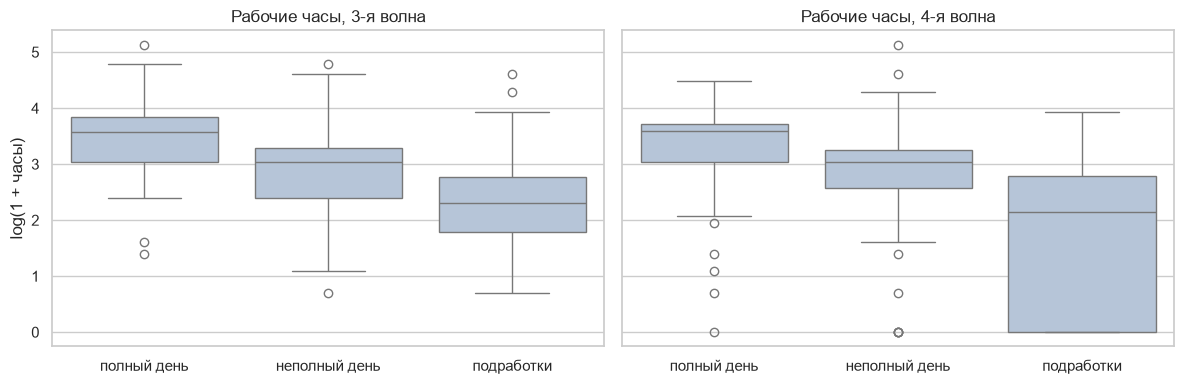

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, w in zip(axes, ['3', '4']):
    sns.boxplot(data=d[d[f'emp_{w}'].eq(1)], x=f'fmt_{w}', y=f'loghours_{w}', ax=ax,
                order=FORMAT_ORDER[1:], color='lightsteelblue')
    ax.set(title=f'Рабочие часы, {w}-я волна', xlabel='', ylabel='log(1 + часы)')
plt.tight_layout()
plt.show()

**Вывод.** Медианы различаются ожидаемо: полный день — около 35 часов, неполный — 20, подработки — 8–9. Выбросы единичные.

### 10.3. Сон

Коды: отбой 1 = 20:00 … 11 = 6:00 → `19 + код` часов (24 = 0:00); пробуждение 1 = 3:00 … 12 = 14:00 → `26 + код`.
- Интервал ≤ 0 — значение не определено.
- Крайние варианты шкалы (отбой 6:00, пробуждение 14:00) могут означать «в это время или позже» — цензурирование.
- Интервал < 4 ч и > 12 ч помечается флагом.

Переводим коды сна в часы и считаем длительность и середину сна.

In [20]:
SLEEP_ITEMS = {'3': ('sleep1_3w', 'sleep2_3w', 'sleep3_3w', 'sleep4_3w'),
               '4': ('sleep1_4w', 'sleep2_4w', 'sleep3_4w', 'sleep4_4w')}
sleep_rows = []
for w, (bed_wd, bed_we, wake_wd, wake_we) in SLEEP_ITEMS.items():
    for day, bed_item, wake_item in [('wd', bed_wd, wake_wd), ('we', bed_we, wake_we)]:
        bed, wake = valid(bed_item), valid(wake_item)
        bed_hour, wake_hour = 19 + bed, 26 + wake
        duration = wake_hour - bed_hour
        d[f'sleep_dur_{day}_{w}'] = duration.where(duration > 0)
        d[f'sleep_mid_{day}_{w}'] = ((bed_hour + wake_hour) / 2).where(duration > 0)
        d[f'sleep_{day}_{w}_invalid'] = duration <= 0
        d[f'sleep_{day}_{w}_short'] = duration.between(0.5, 3.5)
        d[f'sleep_{day}_{w}_long'] = duration > 12
        d[f'sleep_{day}_{w}_censored'] = bed.eq(11) | wake.eq(12)
        n = duration.notna().sum()
        sleep_rows.append({'волна': w, 'дни': 'будни' if day == 'wd' else 'выходные', 'n': n,
                           'интервал ≤ 0': (duration <= 0).sum(), '< 4 ч': d[f'sleep_{day}_{w}_short'].sum(),
                           '> 12 ч': (duration > 12).sum(), 'отбой 6:00, %': bed.eq(11).sum() / n * 100,
                           'подъём 14:00, %': wake.eq(12).sum() / n * 100})
    d[f'sjl_{w}'] = (d[f'sleep_mid_we_{w}'] - d[f'sleep_mid_wd_{w}']).abs()
pd.DataFrame(sleep_rows).set_index(['волна', 'дни']).round(1)

n  интервал ≤ 0  < 4 ч  > 12 ч  отбой 6:00, %  \
волна дни                                                          
3     будни     1208             8     27      10            2.3   
      выходные  1208             7     11      23            3.6   
4     будни      911             7     15       5            2.9   
      выходные   911            10      9      12            4.9   

                подъём 14:00, %  
волна дни                        
3     будни                 1.8  
      выходные              7.3  
4     будни                 1.9  
      выходные              5.8

**Вывод.** Неопределённых интервалов (≤ 0) всего 32. Сон короче 4 и длиннее 12 часов встречается редко и помечен флагом. В выходные 6–7% выбрали крайний вариант «подъём в 14:00» — эти значения отмечены как цензурированные.

### 10.4. Социальные характеристики

- `ses1`: 1–3 — «трудности с повседневными расходами», 4, 5, 6 — отдельные категории; код 7 «нет родителей» не входит в шкалу.
- `bigmajor`: коды 4 (сельское хозяйство) и 8 (искусство) содержат 2–9 человек в волне и исключаются из моделей с поправкой на направление. Референтная категория — инженерные.

Перекодируем социальные характеристики, которые используются как поправки в моделях.

In [21]:
d['ses_noparents'] = d['ses1'].eq(7)
d['ses'] = d['ses1'].where(~d['ses_noparents'])
d['ses4'] = pd.Categorical(d['ses'].map({1: '1–3', 2: '1–3', 3: '1–3', 4: '4', 5: '5', 6: '6'}),
                           categories=['1–3', '4', '5', '6'], ordered=True)
d['funding_c'] = pd.Categorical(d['funding'].map({1: 'бюджет', 2: 'платное', 3: 'целевое'}),
                                categories=['бюджет', 'платное', 'целевое'])
d['sex_c'] = pd.Categorical(d['sex'].map({1: 'мужской', 2: 'женский'}), categories=['мужской', 'женский'])
d['major_c'] = pd.Categorical(
    d['bigmajor'].map({1: 'естественные', 2: 'инженерные', 5: 'общественные', 7: 'гуманитарные'}),
    categories=['инженерные', 'естественные', 'общественные', 'гуманитарные'])

controls = d.loc[d['in_study'], ['sex_c', 'major_c', 'funding_c', 'ses4']]
pd.concat({c: controls[c].value_counts(dropna=False) for c in controls}, names=['переменная', 'категория']).to_frame('n')

n
переменная категория        
sex_c      мужской       795
           женский       626
           nan           601
major_c    инженерные    785
           nan           595
           естественные  224
           общественные  212
           гуманитарные  206
funding_c  бюджет        964
           nan           792
           платное       218
           целевое        48
ses4       nan           981
           5             470
           6             283
           4             173
           1–3           115

**Вывод.** Пропусков много: материальное положение не указано у 981 из 2 022, финансирование — у 792. Эти пропуски восстанавливаются в разделе 15. Целевое обучение — всего 48 человек.

### Правила кодирования открытых ответов

1. Единица кодирования — один ответ. Решение принимается по тексту; ответы того же человека на закрытые вопросы для решения не используются.
2. Перенос в вариант анкеты — только если текст однозначно подпадает под формулировку **ровно одного** варианта.
3. Если подходят несколько вариантов или назван не один мотив — остаётся «другое» с описательным кодом «несколько мотивов».
4. Отрасль без указания положения в занятости («общепит», «доставка») не переносится в варианты «наёмный работник», «предприниматель», «фриланс».
5. Всем оставшимся в «другом» присваивается один описательный код из фиксированного списка.
6. Ответ, противоречащий закрытому ответу («не работаю» у работающего), — код «противоречие» и флаг `CONS`; закрытые ответы не меняются.
7. Ответ без содержания — «бессмысленный ответ», отказ уточнять — «отказ»; такие ответы не кодируются.
8. Регистр, транслит и опечатки не учитываются.
9. Основной анализ — по исходным категориям анкеты; перенесённые ответы используются в проверке устойчивости.
10. Кодирование выполнено одним исследователем; все решения и основания приведены в таблице `open_answers`.

### 10.5. Мотивы трудоустройства

Исходные пять вариантов и «другое» сохраняются (`motive_raw_*`). Группировки задаются отдельно под гипотезы:
- **Г1.4** (`motive_g14_*`): «содержать себя» / «опыт и интерес» / «оплата обучения» / «доп. доход»;
- **Г3.4–3.5** (`motive_g35_*`): «содержание себя и оплата обучения» / «опыт и интерес» / «доп. доход».

Открытые ответы 4-й волны переносятся в исходный код только при однозначном соответствии (`motive_rec_4` — для проверки устойчивости).

Кодируем мотивы работы и переносим однозначные открытые ответы.

In [22]:
WORK_MOTIVE = {1: 'оплата обучения', 2: 'содержать себя', 3: 'доп. доход', 4: 'опыт', 5: 'интерес', 88: 'другое'}
GROUP_G14 = {'содержать себя': 'содержать себя', 'опыт': 'опыт и интерес', 'интерес': 'опыт и интерес',
             'оплата обучения': 'оплата обучения', 'доп. доход': 'доп. доход'}
GROUP_G35 = {'содержать себя': 'содержание себя и оплата обучения', 'оплата обучения': 'содержание себя и оплата обучения',
             'опыт': 'опыт и интерес', 'интерес': 'опыт и интерес', 'доп. доход': 'доп. доход'}

# Открытые ответы: (код после перекодировки, описательный код, основание).
# Код 88 — остаётся «другое»; None — ответ не кодируется (противоречие или бессмыслица).
OPEN_MOTIVE = {
    'Надо за квартиру платить и кушать': (2, 'содержать себя', 'оплата жилья и еды = содержать себя'),
    'Стипендии нет на жизнь нужны деньги на продукты и на повседневную жизнь материальная помощь от университета '
    'мизерная копейки и нет смысла ждать по 3 месяца что бы получить и если одобрят получить эти копейки':
        (2, 'содержать себя', 'деньги на продукты и повседневную жизнь = содержать себя'),
    'заработать на исполнение своих желания': (3, 'доп. доход', 'заработок сверх необходимого = доп. доход'),
    'Коплю на языковой год в Китае': (1, 'оплата обучения', 'обучение за пределами университета = вариант 1'),
    'платить кредит': (88, 'обязательные платежи', 'неясно, чей кредит и на что: содержать себя или доп. доход'),
    'жилье': (88, 'обязательные платежи', 'одно слово: оплата или покупка жилья'),
    'коплю на первый взнос по ипотеке': (88, 'накопление на покупку', 'крупная покупка: нет подходящего варианта'),
    'семейная необходимость': (88, 'нужды семьи', 'нужды семьи, а не свои: нет подходящего варианта'),
    'помощь в семейном деле': (88, 'нужды семьи', 'семейное дело: нет подходящего варианта'),
    'нравится научная деятельность + написание диплома': (88, 'связь с учёбой', 'интерес и учебная необходимость — два мотива'),
    'Пригласили после прохождения производственной практике': (88, 'связь с учёбой', 'обстоятельство, а не мотив'),
    'Так как работа - часть практики в университете': (88, 'связь с учёбой', 'работа как часть учебного плана'),
    'Практика': (88, 'связь с учёбой', 'работа как часть учебного плана'),
    'это дает мне больше возможностей при работе над своим учебно-исследовательским проектом':
        (88, 'связь с учёбой', 'польза для учебного проекта: нет подходящего варианта'),
    'чтобы заниматься чем-то ещё, кроме учёбы': (88, 'занятость сама по себе', 'нет подходящего варианта'),
    'все перечисленное': (88, 'несколько мотивов', 'подходят несколько вариантов'),
    'Возможность получить профессиональный опыт и содержать себя': (88, 'несколько мотивов', 'варианты 2 и 4'),
    'финансовая независимость, получение практического опыта, карьерные перспективы (знакомства с работодателями '
    'и возможность трудоустройства после выпуска), развитие гибких навыков, повышение уверенности в себе '
    '(осознание своей способности справляться с нагрузкой)': (88, 'несколько мотивов', 'варианты 2 и 4 и другие'),
    'сейчас не работаю': (None, 'противоречие', 'противоречит ответу о наличии работы'),
    'фывапро': (None, 'бессмысленный ответ', 'нет содержательной информации'),
}
missing_rules = set(d['work4_4w_88'].dropna()) - set(OPEN_MOTIVE)
assert not missing_rules, f'Нет правила для ответов: {missing_rules}'

for w, source in [('3', 'work4'), ('4', 'work4_4w')]:
    motive = d[source].where(d[f'{source}_st'].isin(['VALID', 'OTHER'])).map(WORK_MOTIVE)
    d[f'motive_raw_{w}'] = pd.Categorical(motive, categories=list(WORK_MOTIVE.values()))
    d[f'motive_g14_{w}'] = motive.map(GROUP_G14)
    d[f'motive_g35_{w}'] = motive.map(GROUP_G35)
    d[f'pay_tuition_{w}'] = motive.eq('оплата обучения').astype(float).where(motive.notna())

open_code = d['work4_4w_88'].map(lambda text: OPEN_MOTIVE[text][0] if pd.notna(text) else np.nan)
d['motive_open_conflict_4'] = d['work4_4w_88'].eq('сейчас не работаю')
d['motive_open_invalid_4'] = d['work4_4w_88'].eq('фывапро')
recoded = d['work4_4w'].where(d['work4_4w_st'].isin(['VALID', 'OTHER']))
transfer = recoded.eq(88) & open_code.notna() & open_code.ne(88)
recoded = recoded.mask(transfer, open_code).map(WORK_MOTIVE)
d['motive_rec_4'] = pd.Categorical(recoded, categories=list(WORK_MOTIVE.values()))
d['motive_g14_rec_4'] = recoded.map(GROUP_G14)
d['motive_g35_rec_4'] = recoded.map(GROUP_G35)

pd.DataFrame({'3-я волна': d['motive_raw_3'].value_counts(), '4-я волна': d['motive_raw_4'].value_counts(),
              '4-я, после перекодировки': d['motive_rec_4'].value_counts()})

,3-я волна,4-я волна,"4-я, после перекодировки"
оплата обучения,12,12,13
содержать себя,179,169,171
доп. доход,183,124,125
опыт,87,82,82
интерес,56,33,33
другое,16,20,16


**Вывод.** Самые частые мотивы — «содержать себя» и «доп. доход». «Оплату обучения» называют всего по 12 человек в волне, поэтому в группировках её объединяют с другими мотивами. Из 20 открытых ответов 4-й волны перенесены 4.

### 10.6. Сфера работы и открытые ответы о ней

Открытые ответы 4-й волны переносятся в закрытую категорию только при однозначном соответствии; иначе остаются «другим» с описательным кодом отрасли. Отрасль («общепит», «доставка») не определяет положение в занятости.

Кодируем сферу работы и открытые ответы о ней.

In [23]:
SPHERE = {1: 'образование', 2: 'наука', 3: 'бизнес: наёмный работник', 4: 'бизнес: предприниматель',
          5: 'госуправление', 6: 'общественные и политические организации', 7: 'СМИ', 8: 'фриланс', 88: 'другое'}
for w, source in [('3', 'work2_3w'), ('4', 'work2_4w')]:
    sphere = d[source].where(d[f'{source}_st'].isin(['VALID', 'OTHER'])).map(SPHERE)
    d[f'sphere_{w}'] = pd.Categorical(sphere, categories=list(SPHERE.values()))

# (шаблон, код после перекодировки, описательный код, основание); применяется первое совпадение
SPHERE_RULES = [
    (r'^учитель, репетитор$', 1, 'образование', 'преподавание = образование'),
    (r'не работаю', None, 'противоречие', 'противоречит ответу о наличии работы'),
    (r'не хочу говорить', None, 'отказ', 'отказ от уточнения'),
    (r'общепит|obschepit|кухня', 88, 'общепит', 'отрасль; положение в занятости не указано'),
    (r'доставка|курьер|склад|сортировоч', 88, 'логистика и доставка', 'отрасль; положение в занятости не указано'),
    (r'продаж|торговл', 88, 'торговля', 'отрасль; положение в занятости не указано'),
    (r'^it$|компы|автоматизац|электроник|сайт', 88, 'IT и электроника', 'отрасль; положение в занятости не указано'),
    (r'инженер|энергетик|строител|добыча|завод|детал|мебель|разнорабоч', 88,
     'производство, строительство, инженерия', 'отрасль; положение в занятости не указано'),
    (r'спорт', 88, 'спорт', 'отрасль; положение в занятости не указано'),
    (r'культур|рисован|музык', 88, 'культура и творчество', 'отрасль; положение в занятости не указано'),
    (r'реклам|маркетинг', 88, 'реклама и маркетинг', 'отрасль; положение в занятости не указано'),
    (r'медицин|психолог', 88, 'здравоохранение и психология', 'отрасль; положение в занятости не указано'),
    (r'государственная служба и некоммерческие', 88, 'госслужба или НКО', 'подходят два варианта анкеты (5 и 6)'),
    (r'^обслуживания$', 88, 'сфера обслуживания', 'отрасль; положение в занятости не указано'),
    (r'^работы$|разных местах', 88, 'неопределённо', 'отрасль определить нельзя'),
    (r'^[\d\W_]+$|балдеж', None, 'бессмысленный ответ', 'нет содержательной информации'),
]


def code_sphere(text):
    '''Код, описательный код и основание для открытого ответа о сфере.'''
    if pd.isna(text):
        return pd.Series([np.nan, None, None])
    lowered = str(text).strip().lower()
    for pattern, new_code, description, basis in SPHERE_RULES:
        if re.search(pattern, lowered):
            return pd.Series([new_code, description, basis])
    return pd.Series([88, 'не закодировано', 'нет правила'])


sphere_open = d['work2_4w_88'].apply(code_sphere)
sphere_open.columns = ['код', 'описательный код', 'основание']
d['sphere_desc_4'] = sphere_open['описательный код']
d['sphere_open_conflict_4'] = d['sphere_desc_4'].eq('противоречие')
recoded = d['work2_4w'].where(d['work2_4w_st'].isin(['VALID', 'OTHER']))
transfer = recoded.eq(88) & sphere_open['код'].notna() & sphere_open['код'].ne(88)
d['sphere_rec_4'] = pd.Categorical(recoded.mask(transfer, sphere_open['код']).map(SPHERE),
                                   categories=list(SPHERE.values()))

pd.DataFrame({'3-я волна': d['sphere_3'].value_counts(), '4-я волна': d['sphere_4'].value_counts(),
              '4-я, после перекодировки': d['sphere_rec_4'].value_counts()})

,3-я волна,4-я волна,"4-я, после перекодировки"
образование,96,71,72
наука,53,50,50
бизнес: наёмный работник,113,132,132
бизнес: предприниматель,16,16,16
госуправление,17,8,8
общественные и политические организации,8,13,13
СМИ,17,11,11
фриланс,109,83,83
другое,0,56,55


**Вывод.** Чаще всего — наёмная работа в бизнесе, фриланс и образование. Из 56 ответов «другое» в 4-й волне перенесён только 1 («учитель, репетитор»), остальные получили описательный код отрасли.

Таблица всех открытых ответов с предложенным кодом и основанием решения — для проверки вторым кодировщиком.

In [24]:
# Все открытые ответы с предложенным кодом и основанием — для двойного кодирования
motive_texts = d['work4_4w_88'].dropna()
open_answers = pd.concat([
    pd.DataFrame({'поле': 'мотив (work4_4w_88)', 'текст': motive_texts,
                  'предложенный код': motive_texts.map(lambda t: OPEN_MOTIVE[t][0]),
                  'описательный код': motive_texts.map(lambda t: OPEN_MOTIVE[t][1]),
                  'основание': motive_texts.map(lambda t: OPEN_MOTIVE[t][2])}),
    pd.DataFrame({'поле': 'сфера (work2_4w_88)', 'текст': d['work2_4w_88'].dropna()})
    .join(sphere_open.rename(columns={'код': 'предложенный код'})),
]).rename_axis('строка')
open_answers

,поле,текст,предложенный код,описательный код,основание
строка,,,,,
59,мотив (work4_4w_88),Надо за квартиру платить и кушать,2.0,содержать себя,оплата жилья и еды = содержать себя
430,мотив (work4_4w_88),помощь в семейном деле,88.0,нужды семьи,семейное дело: нет подходящего варианта
493,мотив (work4_4w_88),нравится научная деятельность + написание диплома,88.0,связь с учёбой,интерес и учебная необходимость — два мотива
553,мотив (work4_4w_88),Коплю на языковой год в Китае,1.0,оплата обучения,обучение за пределами университета = вариант 1
561,мотив (work4_4w_88),"финансовая независимость, получение практического опыта, карьерные перспекти...",88.0,несколько мотивов,варианты 2 и 4 и другие
572,мотив (work4_4w_88),заработать на исполнение своих желания,3.0,доп. доход,заработок сверх необходимого = доп. доход
610,мотив (work4_4w_88),платить кредит,88.0,обязательные платежи,"неясно, чей кредит и на что: содержать себя или доп. доход"
673,мотив (work4_4w_88),жилье,88.0,обязательные платежи,одно слово: оплата или покупка жилья
823,мотив (work4_4w_88),Возможность получить профессиональный опыт и содержать себя,88.0,несколько мотивов,варианты 2 и 4


**Вывод.** 20 ответов о мотиве и 56 о сфере; у каждого записано основание решения.

#### Анализ открытых ответов

Открытые ответы анализируются описательно:
1. каждый ответ вместе с ответами того же человека на закрытые вопросы;
2. итоговые решения по мотивам и описательные коды по сфере;
3. кто стоит за каждым описательным кодом (формат, часы, соответствие специальности, польза и трудности);
4. чем выбравшие «другое» отличаются от выбравших закрытые варианты;
5. все тексты по каждому коду — для цитирования.

Добавляем к каждому открытому ответу ответы того же человека на закрытые вопросы.

In [25]:
CONTEXT = {'fmt_4': 'формат', 'hours_4': 'часы', 'motive_raw_4': 'мотив (закрытый)', 'sphere_4': 'сфера (закрытая)',
           'fit_4': 'соответствие специальности', 'benefit_4': 'польза для учёбы', 'difficulty_4': 'трудно совмещать',
           'sex_c': 'пол', 'major_c': 'направление', 'funding_c': 'финансирование'}
open_context = open_answers.join(d[list(CONTEXT)].rename(columns=CONTEXT))


def decision(row):
    '''Итоговая категория анкеты для открытого ответа.'''
    if pd.isna(row['предложенный код']):
        return 'не кодируется'
    labels = WORK_MOTIVE if row['поле'].startswith('мотив') else SPHERE
    return labels[row['предложенный код']]


open_context['решение'] = open_context.apply(decision, axis=1)
open_context

,поле,текст,предложенный код,описательный код,основание,формат,часы,мотив (закрытый),сфера (закрытая),соответствие специальности,польза для учёбы,трудно совмещать,пол,направление,финансирование,решение
строка,,,,,,,,,,,,,,,,
59,мотив (work4_4w_88),Надо за квартиру платить и кушать,2.0,содержать себя,оплата жилья и еды = содержать себя,неполный день,48.0,другое,другое,1.0,2.0,3.0,NaN,NaN,NaN,содержать себя
430,мотив (work4_4w_88),помощь в семейном деле,88.0,нужды семьи,семейное дело: нет подходящего варианта,неполный день,168.0,другое,другое,NaN,3.0,NaN,NaN,NaN,NaN,другое
493,мотив (work4_4w_88),нравится научная деятельность + написание диплома,88.0,связь с учёбой,интерес и учебная необходимость — два мотива,неполный день,6.0,другое,наука,4.0,2.0,2.0,женский,естественные,NaN,другое
553,мотив (work4_4w_88),Коплю на языковой год в Китае,1.0,оплата обучения,обучение за пределами университета = вариант 1,подработки,6.0,другое,образование,3.0,4.0,1.0,женский,общественные,NaN,оплата обучения
561,мотив (work4_4w_88),"финансовая независимость, получение практического опыта, карьерные перспекти...",88.0,несколько мотивов,варианты 2 и 4 и другие,подработки,10.0,другое,фриланс,4.0,3.0,1.0,женский,общественные,платное,другое
572,мотив (work4_4w_88),заработать на исполнение своих желания,3.0,доп. доход,заработок сверх необходимого = доп. доход,неполный день,30.0,другое,бизнес: наёмный работник,1.0,1.0,2.0,женский,общественные,бюджет,доп. доход
610,мотив (work4_4w_88),платить кредит,88.0,обязательные платежи,"неясно, чей кредит и на что: содержать себя или доп. доход",неполный день,9.0,другое,образование,2.0,1.0,3.0,женский,гуманитарные,бюджет,другое
673,мотив (work4_4w_88),жилье,88.0,обязательные платежи,одно слово: оплата или покупка жилья,подработки,10.0,другое,другое,1.0,1.0,4.0,мужской,инженерные,NaN,другое
823,мотив (work4_4w_88),Возможность получить профессиональный опыт и содержать себя,88.0,несколько мотивов,варианты 2 и 4,подработки,0.0,другое,другое,3.0,4.0,2.0,мужской,естественные,NaN,другое


**Вывод.** Каждый открытый ответ можно читать в контексте: формат, часы, соответствие специальности, польза и трудности.

Итоговые решения по открытым ответам.

In [26]:
# Итоговые решения: мотивы — какой вариант анкеты; сфера — описательный код отрасли
motive_open = open_context[open_context['поле'].str.startswith('мотив')]
sphere_open_ctx = open_context[open_context['поле'].str.startswith('сфера')]
display(motive_open.groupby(['решение', 'описательный код']).size().to_frame('ответов'))
sphere_open_ctx['описательный код'].value_counts().to_frame('ответов')

ответов
решение         описательный код               
доп. доход      доп. доход                    1
другое          занятость сама по себе        1
                накопление на покупку         1
                несколько мотивов             3
                нужды семьи                   2
                обязательные платежи          2
                связь с учёбой                5
не кодируется   бессмысленный ответ           1
                противоречие                  1
оплата обучения оплата обучения               1
содержать себя  содержать себя                2

,ответов
описательный код,
общепит,9
"производство, строительство, инженерия",8
логистика и доставка,7
IT и электроника,6
торговля,4
бессмысленный ответ,3
спорт,3
культура и творчество,3
неопределённо,2


**Вывод.** Мотивы: 4 перенесены, 14 остались «другим» (чаще всего «связь с учёбой» — 5), 2 не кодируются. Сфера: чаще всего общепит (9), производство и инженерия (8), логистика и доставка (7).

Описываем, кто стоит за каждым описательным кодом сферы.

In [27]:
# Кто стоит за каждым описательным кодом сферы
sphere_profile = sphere_open_ctx.groupby('описательный код').agg(
    ответов=('текст', 'size'),
    **{'медиана часов': ('часы', 'median'),
       'полный день': ('формат', lambda s: s.eq('полный день').sum()),
       'неполный день': ('формат', lambda s: s.eq('неполный день').sum()),
       'подработки': ('формат', lambda s: s.eq('подработки').sum()),
       'соответствие специальности (1–4)': ('соответствие специальности', 'mean'),
       'польза для учёбы (1–4)': ('польза для учёбы', 'mean'),
       'трудно совмещать (1–4)': ('трудно совмещать', 'mean')})
sphere_profile.sort_values('ответов', ascending=False).round(1)

,ответов,медиана часов,полный день,неполный день,подработки,соответствие специальности (1–4),польза для учёбы (1–4),трудно совмещать (1–4)
описательный код,,,,,,,,
общепит,9,30.0,4,2,3,1.4,1.9,2.3
"производство, строительство, инженерия",8,16.0,1,3,4,2.4,2.8,2.3
логистика и доставка,7,16.0,0,3,4,1.3,1.4,2.6
IT и электроника,6,20.0,0,5,1,3.2,2.7,2.7
торговля,4,27.5,1,1,2,1.2,2.2,2.8
бессмысленный ответ,3,17.5,1,1,1,1.0,1.0,2.3
культура и творчество,3,12.0,0,0,3,1.7,2.3,2.7
спорт,3,15.0,0,1,2,1.0,2.3,1.3
здравоохранение и психология,2,5.5,0,0,2,2.5,4.0,3.0


**Вывод.** В общепите больше часов (медиана 30) и низкое соответствие специальности (1,4 из 4). Группы малы (1–9 ответов), поэтому это описание, а не статистический вывод.

Сравниваем выбравших «другое» с выбравшими закрытые варианты.

In [28]:
# Чем выбравшие «другое» отличаются от выбравших закрытые варианты (работающие, 4-я волна)
workers_4 = d[d['emp_4'].eq(1)]


def describe_group(frame):
    return pd.Series({'n': len(frame), 'медиана часов': frame['hours_4'].median(),
                      'полный день, %': frame['fmt_4'].eq('полный день').mean() * 100,
                      'подработки, %': frame['fmt_4'].eq('подработки').mean() * 100,
                      'соответствие специальности': frame['fit_4'].mean(),
                      'польза для учёбы': frame['benefit_4'].mean(),
                      'трудно совмещать': frame['difficulty_4'].mean(),
                      'платное обучение, %': frame['funding_c'].eq('платное').mean() * 100})


by_sphere = workers_4.groupby('sphere_4', observed=True).apply(describe_group)
by_motive = workers_4.groupby('motive_raw_4', observed=True).apply(describe_group)
display(by_sphere.round(1).rename_axis('сфера (закрытый вариант)'))
by_motive.round(1).rename_axis('мотив (закрытый вариант)')

,n,медиана часов,"полный день, %","подработки, %",соответствие специальности,польза для учёбы,трудно совмещать,"платное обучение, %"
сфера (закрытый вариант),,,,,,,,
образование,71.0,12.0,18.3,31.0,2.6,2.7,2.2,16.9
наука,50.0,16.0,14.0,22.0,3.3,3.1,1.9,8.0
бизнес: наёмный работник,132.0,20.0,25.0,28.8,2.5,2.6,2.2,19.7
бизнес: предприниматель,16.0,20.0,25.0,43.8,1.9,2.3,2.0,12.5
госуправление,8.0,20.0,50.0,12.5,3.0,2.9,2.1,0.0
общественные и политические организации,13.0,35.0,53.8,23.1,2.3,2.7,3.0,7.7
СМИ,11.0,20.0,18.2,45.5,1.7,2.4,2.1,9.1
фриланс,83.0,10.0,7.2,69.9,2.3,2.5,2.1,13.3
другое,56.0,19.0,14.3,44.6,1.9,2.3,2.3,5.4


,n,медиана часов,"полный день, %","подработки, %",соответствие специальности,польза для учёбы,трудно совмещать,"платное обучение, %"
мотив (закрытый вариант),,,,,,,,
оплата обучения,12.0,15.0,66.7,16.7,2.2,2.5,2.0,8.3
содержать себя,169.0,20.0,22.5,32.5,2.3,2.5,2.5,15.4
доп. доход,124.0,12.0,5.6,58.1,2.1,2.5,2.0,14.5
опыт,82.0,20.0,28.0,19.5,3.3,3.1,1.8,9.8
интерес,33.0,12.0,18.2,57.6,2.3,2.8,2.0,15.2
другое,20.0,16.0,10.0,30.0,2.7,2.4,2.0,10.0


**Вывод.** Выбравшие «другое» в вопросе о сфере чаще работают на подработках (45%) и реже считают работу связанной со специальностью (1,9 из 4). По мотивам «другое» заметно не выделяется.

Все тексты по каждому коду — для цитирования в статье.

In [29]:
# Все тексты по каждому коду — для цитирования
quotes = pd.concat([
    motive_open.groupby('описательный код')['текст'].agg(lambda t: ' | '.join(t)).rename_axis('код').to_frame().assign(поле='мотив'),
    sphere_open_ctx.groupby('описательный код')['текст'].agg(lambda t: ' | '.join(t)).rename_axis('код').to_frame()
    .assign(поле='сфера'),
]).set_index('поле', append=True).swaplevel()
quotes

текст
поле  код                                                                                                                    
мотив бессмысленный ответ                                                                                             фывапро
      доп. доход                                                                       заработать на исполнение своих желания
      занятость сама по себе                                                         чтобы заниматься чем-то ещё, кроме учёбы
      накопление на покупку                                                                  коплю на первый взнос по ипотеке
      несколько мотивов                       финансовая независимость, получение практического опыта, карьерные перспекти...
      нужды семьи                                                             помощь в семейном деле | семейная необходимость
      обязательные платежи                                                                             платить кредит | жилье
      оплата обучения                                                                           Коплю на языковой год в Китае
      противоречие                                                                                          сейчас не работаю
      связь с учёбой                          нравится научная деятельность + написание диплома | Пригласили после прохожд...
      содержать себя                          Надо за квартиру платить и кушать | Стипендии нет на жизнь нужны деньги на п...
сфера IT и электроника                        Развитие киберспорта (являюсь техническим специалистом - отвечаю за создание...
      бессмысленный ответ                                                                    67543 | --- | балдеж и раскайфос
      госслужба или НКО                                                   Государственная служба и некоммерческие организации
      здравоохранение и психология                                                                      Медицина | Психология
      культура и творчество                     культура и творчество | Культура (играю в музыкальном коллективе) | рисование
      логистика и доставка                    Складской персонал | доставка | Склад | курьер | доставка | Специалист сорти...
      неопределённо                                                                                    Работы | разных местах
      образование                                                                                          Учитель, репетитор
      общепит                                 Общепит | obschepit | Общепит | Общепит | кухня | Общепит | общепит | общепи...
      отказ                                                                                               не хочу говорить :)
      производство, строительство, инженерия  Разнорабочий | Инженерия и проектирование | Энергетика | Строительная | Добы...
      противоречие                                                                                    не работаю | не работаю
      реклама и маркетинг                                                                        реклама | инфлюенс-маркетинг
      спорт                                                                Спортивная деятельность | Спорт | Спортивный судья
      сфера обслуживания                                                                          обслуживания | Обслуживания
      торговля                                                         сфера продаж | Продажи | Торговля | Розничная торговля

### 10.7. Стажировки, спорт, курение и алкоголь, повторный выбор, намерения

Строим переменные стажировок, спорта, курения и алкоголя, повторного выбора образования и намерений.

In [30]:
for w, has, course, paid in [('3', 'intern1', 'intern2', 'intern3'), ('4', 'intern1_4w', 'intern2_4w', 'intern3_4w')]:
    d[f'intern_{w}'] = binary(valid(has))
    d[f'intern_course_{w}'] = valid(course)
    d[f'intern_paid_{w}'] = binary(valid(paid))

# Мотивы стажировки кодированы иначе, чем мотивы работы: соответствие — по тексту вариантов
INTERN_MOTIVE = {1: 'содержать себя', 2: 'доп. доход', 3: 'опыт', 4: 'интерес', 88: 'другое'}
GROUP_G44 = {'опыт': 'опыт и интерес', 'интерес': 'опыт и интерес',
             'содержать себя': 'содержание себя и доп. доход', 'доп. доход': 'содержание себя и доп. доход'}
intern_motive = d['intern4'].where(d['intern4_st'].isin(['VALID', 'OTHER'])).map(INTERN_MOTIVE)
d['intern_motive_raw_3'] = pd.Categorical(intern_motive, categories=list(INTERN_MOTIVE.values()))
d['intern_motive_g44_3'] = intern_motive.map(GROUP_G44)
d['intern_fit_3'] = valid('intern5_1')
d['intern_benefit_3'] = valid('intern5_2')
d['intern_harm_3'] = valid('intern5_3')
d['intern_difficulty_3'] = valid('intern5_4')
d['intern_fit_4'] = valid('intern_major1_4w')

# Спорт; частота — только в 3-й волне (больше = чаще)
d['pe_3'] = binary(valid('pe_3w_1'))
d['pe_4'] = binary(valid('pe_4w'))
d['pe_freq_3'] = 6 - valid('pe_3w_2')

# Курение и алкоголь: отказы и пустые ответы остаются в статусе и не входят в основные сравнения
for w in ['3', '4']:
    d[f'smoke_{w}'] = binary(valid(f'smoking_{w}w'))
    d[f'alco_{w}'] = binary(valid(f'alco_{w}w'))

EDU3 = {1: 'тот же вуз, та же специальность', 2: 'тот же вуз, другая специальность',
        3: 'другой вуз, та же специальность', 4: 'другой вуз, другая специальность', 5: 'не поступал бы'}
for w in ['3', '4']:
    d[f'edu3_{w}'] = pd.Categorical(valid(f'edu3_{w}w').map(EDU3), categories=list(EDU3.values()))

d['intent_3'] = binary(valid('work_intentions'))
d['intent_4'] = binary(valid('work_intentions_4w'))

new_vars = ['intern_3', 'intern_4', 'intern_paid_3', 'intern_paid_4', 'intern_fit_3', 'intern_benefit_3',
            'intern_harm_3', 'intern_difficulty_3', 'intern_fit_4', 'pe_3', 'pe_4', 'pe_freq_3',
            'smoke_3', 'smoke_4', 'alco_3', 'alco_4', 'intent_3', 'intent_4']
d[new_vars].describe().T[['count', 'mean', 'min', 'max']]

,count,mean,min,max
intern_3,1211.0,0.199009,0.0,1.0
intern_4,913.0,0.282585,0.0,1.0
intern_paid_3,241.0,0.593361,0.0,1.0
intern_paid_4,258.0,0.527132,0.0,1.0
intern_fit_3,232.0,3.000000,1.0,4.0
intern_benefit_3,219.0,2.735160,1.0,4.0
intern_harm_3,223.0,1.887892,1.0,4.0
intern_difficulty_3,218.0,2.055046,1.0,4.0
intern_fit_4,243.0,3.193416,1.0,4.0
pe_3,1208.0,0.716060,0.0,1.0


**Вывод.** Стажировку проходили 20% в 3-й волне и 28% в 4-й; оплачиваемыми были 59% и 53% стажировок. Спортом занимаются 72% и 59%, курят 24% и 23%.

### 10.8. Планируемое распределение времени (3-я волна)

Корректный блок — сумма шести долей равна 100. Нулевые доли — содержательные ответы и сохраняются. Для работы отдельно выделяются наличие доли > 0 (Г6.3) и её величина среди указавших > 0.

Переводим планируемое распределение времени в доли.

In [31]:
ALLOC_NAMES = {1: 'учёба', 2: 'клубы', 3: 'работа', 4: 'волонтёрство', 5: 'курсы', 6: 'остальное'}
alloc_ok = d['hours_3w_1_st'].eq('VALID')
for i, name in ALLOC_NAMES.items():
    d[f'alloc_{name}_3'] = (d[f'hours_3w_{i}'] / 100).where(alloc_ok)
d['plan_work_pos_3'] = (d['alloc_работа_3'] > 0).astype(float).where(alloc_ok)
d['plan_work_share_pos_3'] = d['alloc_работа_3'].where(d['plan_work_pos_3'].eq(1))

ALLOC_COLS = [f'alloc_{name}_3' for name in ALLOC_NAMES.values()]
alloc = d.loc[alloc_ok, ALLOC_COLS]
print(f'Корректных блоков: {alloc_ok.sum()}')
pd.DataFrame({'доля нулей': (alloc == 0).mean(), 'медиана среди > 0': alloc[alloc > 0].median()}).round(2)

Корректных блоков: 1220


,доля нулей,медиана среди > 0
alloc_учёба_3,0.02,0.50
alloc_клубы_3,0.71,0.11
alloc_работа_3,0.44,0.26
alloc_волонтёрство_3,0.89,0.08
alloc_курсы_3,0.63,0.12
alloc_остальное_3,0.26,0.20


**Вывод.** Корректно заполнено 1 220 блоков. На учёбу в среднем планируют половину времени. Нулевую долю на работу указали 44%, поэтому в Г6.3 работа рассматривается как «есть доля / нет доли».

### 10.9. Причины мыслей об отчислении

- 3-я волна: вопрос задавался ответившим «думал, но решил продолжить» (код 2); вариантов «затрудняюсь» и «другое» нет.
- 4-я волна: «затрудняюсь» без причины — статус `DK`; «затрудняюсь» вместе с причиной — флаг противоречия; только «другое» — содержательный ответ без расшифровки.
- Сопоставимое между волнами основание (`reasons_cmp_*`) — отмечена хотя бы одна из семи причин.

Строим переменные причин мыслей об отчислении.

In [32]:
REASONS = {1: 'разочарование в вузе', 2: 'разочарование в направлении', 3: 'академические трудности',
           4: 'отношения с одногруппниками', 5: 'отношения с преподавателями', 6: 'экономические трудности семьи',
           7: 'трудности совмещения с работой'}
dk_only = d['reason_dk_4_txt'] & ~any_box_4w & ~d['reason_other_4_txt']
d.loc[d['reasons_4w_any_st'].eq('VALID') & dk_only, 'reasons_4w_any_st'] = 'DK'
status_3w, status_4w = d['reasons_3w_any_st'], d['reasons_4w_any_st']
d['reason_dk_conflict_4'] = status_4w.eq('VALID') & d['reason_dk_4_txt'] & (any_box_4w | d['reason_other_4_txt'])

for i in REASONS:
    d[f'reason{i}_3'] = d[f'dropout2_3w_1_{i}'].where(status_3w.eq('VALID'))
    d[f'reason{i}_4'] = d[f'dropout2_4w_{i}'].where(status_4w.eq('VALID'))
d['reason_other_4'] = d['reason_other_4_txt'].astype(float).where(status_4w.eq('VALID'))
d['reasons_cmp_3'] = status_3w.eq('VALID')
d['reasons_cmp_4'] = status_4w.eq('VALID') & any_box_4w

reason_shares = pd.DataFrame({
    '3-я волна': [d.loc[d['reasons_cmp_3'], f'reason{i}_3'].mean() for i in REASONS],
    '4-я волна': [d.loc[d['reasons_cmp_4'], f'reason{i}_4'].mean() for i in REASONS],
}, index=list(REASONS.values())).round(3)
display(pd.DataFrame({'3-я волна': status_3w.value_counts(), '4-я волна': status_4w.value_counts()})
        .fillna(0).astype(int).rename_axis('статус блока причин'))
reason_shares.rename_axis('доля среди отметивших ≥ 1 причину')

,3-я волна,4-я волна
статус блока причин,,
DK,0,31
MISS,69,0
NA_SKIP,692,797
NOT_IN_WAVE,4607,4318
NOT_REACHED,1,329
VALID,462,356


,3-я волна,4-я волна
доля среди отметивших ≥ 1 причину,,
разочарование в вузе,0.348,0.400
разочарование в направлении,0.463,0.504
академические трудности,0.500,0.426
отношения с одногруппниками,0.080,0.078
отношения с преподавателями,0.143,0.154
экономические трудности семьи,0.156,0.151
трудности совмещения с работой,0.294,0.330


**Вывод.** Причины указали 462 человека в 3-й волне и 356 в 4-й. Чаще всего — разочарование в направлении и академические трудности. Трудности совмещения с работой называют 29% и 33%.

### 10.10. Переходы между волнами и составные показатели

Строим переходы занятости между волнами и составные показатели для отдельных гипотез.

In [33]:
both_waves = d['emp_3'].notna() & d['emp_4'].notna()
d['trans4'] = pd.Series(np.select(
    [both_waves & d['emp_3'].eq(0) & d['emp_4'].eq(0), both_waves & d['emp_3'].eq(0) & d['emp_4'].eq(1),
     both_waves & d['emp_3'].eq(1) & d['emp_4'].eq(0), both_waves & d['emp_3'].eq(1) & d['emp_4'].eq(1)],
    ['остался неработающим', 'начал работать', 'прекратил работу', 'работал в обеих'], default=None),
    index=d.index)
d['start_work'] = d['emp_4'].where(both_waves & d['emp_3'].eq(0))
d['start_fmt'] = d['fmt_4'].where(d['trans4'].eq('начал работать'))
d['d_hours'] = d['hours_4'] - d['hours_3']
d['d_sleep_wd'] = d['sleep_dur_wd_4'] - d['sleep_dur_wd_3']
d['new_drop_4'] = d['drop_any_4'].where(d['drop_any_3'].eq(0))
for var in ['smoke', 'alco', 'pe']:
    observed = d[f'{var}_3'].notna() & d[f'{var}_4'].notna()
    d[f'{var}_change'] = (d[f'{var}_3'].astype('Int64').astype(str) + '→'
                          + d[f'{var}_4'].astype('Int64').astype(str)).where(observed)

# З3.6: «согласен» = «скорее» или «полностью согласен» (3–4); правило фиксировано до анализа
agree_benefit, agree_difficulty = d['benefit_4'].ge(3), d['difficulty_4'].ge(3)
d['benefit_difficulty_4'] = pd.Series(np.select(
    [agree_benefit & agree_difficulty, agree_benefit & ~agree_difficulty, ~agree_benefit & agree_difficulty],
    ['польза и трудности', 'только польза', 'только трудности'], default='ни того, ни другого'),
    index=d.index).where(d['benefit_4'].notna() & d['difficulty_4'].notna())

# З4.6: сочетания текущей работы и опыта стажировки
for w in ['3', '4']:
    work, intern = d[f'emp_{w}'], d[f'intern_{w}']
    d[f'work_intern_{w}'] = pd.Series(np.select(
        [work.eq(0) & intern.eq(0), work.eq(1) & intern.eq(0), work.eq(0) & intern.eq(1), work.eq(1) & intern.eq(1)],
        ['нет работы, нет стажировки', 'работа без стажировки', 'стажировка без работы', 'работа и стажировка'],
        default=None), index=d.index).where(work.notna() & intern.notna())

display(d['trans4'].value_counts().to_frame('n'))
pd.crosstab(d['fmt_3'], d['fmt_4'], margins=True)

,n
trans4,
остался неработающим,248
работал в обеих,153
начал работать,94
прекратил работу,71


fmt_4,нет работы,полный день,неполный день,подработки,All
fmt_3,,,,,
нет работы,248,14,38,42,342
полный день,5,8,6,1,20
неполный день,27,13,49,18,107
подработки,39,6,19,33,97
All,319,41,112,94,566


**Вывод.** Ответ о работе в обеих волнах есть у 566 человек: 248 не работали ни в одной, 153 работали в обеих, 94 начали работать, 71 прекратили.

## 11. Специальные ответы по группам

Если специальные ответы чаще встречаются в какой-то группе, их исключение из шкальных моделей смещает сравнение групп. Основа — ответы `VALID` и данный код; профили A/B не входят. Критерий χ² Пирсона, при ожидаемой частоте < 5 — перестановочный тест (`scipy.stats.chi2_contingency` с `PermutationMethod`, 20 000 перестановок). Размер эффекта — V Крамера; поправка Холма.

Проверяем, различается ли частота специальных ответов по группам.

In [34]:
SPECIAL = [('satisfaction_4w', 'DK'), ('Work_major_4w', 'DK'), ('intern5_4w_1', 'DK'), ('intern5_4w_2', 'DK'),
           ('intern5_4w_3', 'DK'), ('mark_4w', 'OTHER'), ('work4_4w', 'OTHER'), ('smoking_4w', 'REF'), ('alco_4w', 'REF')]
d['panel_i'] = d['panel'].astype(int)
GROUPS = {'пол': 'sex_c', 'направление': 'major_c', 'финансирование': 'funding_c', 'панель': 'panel_i', 'формат': 'fmt_4'}
permutation = stats.PermutationMethod(n_resamples=20_000, rng=rng)

rows = []
for var, special_code in SPECIAL:
    status = d[f'{var}_st']
    base = status.isin(['VALID', special_code]) & ~d['tech_4w']
    for group_name, group_var in GROUPS.items():
        if group_var == 'fmt_4' and APPLICABILITY.get(var, ('',))[0] == 'work1_4w':
            base_g = base & d['emp_4'].eq(1)
        else:
            base_g = base
        frame = pd.DataFrame({'g': d.loc[base_g, group_var], 'y': status[base_g].eq(special_code)}).dropna()
        table = pd.crosstab(frame['g'].astype(str), frame['y'])
        if table.shape[0] < 2 or table.shape[1] < 2:
            continue
        result = stats.chi2_contingency(table, correction=False)
        method = 'χ²'
        if result.expected_freq.min() < 5:
            result = stats.chi2_contingency(table, correction=False, method=permutation)
            method = 'перестановки'
        n = table.values.sum()
        rows.append({'переменная': var, 'код': special_code, 'группа': group_name, 'n': n, 'k': table[True].sum(),
                     'χ²': result.statistic, 'df': result.dof, 'мин. ожидаемая': result.expected_freq.min(),
                     'метод': method, 'p': result.pvalue,
                     'V Крамера': np.sqrt(result.statistic / (n * (min(table.shape) - 1)))})
special_tests = pd.DataFrame(rows)
special_tests['p (Холм)'] = multipletests(special_tests['p'], method='holm')[1]
special_tests.round(3)

,переменная,код,группа,n,k,χ²,df,мин. ожидаемая,метод,p,V Крамера,p (Холм)
0,satisfaction_4w,DK,пол,785,61,0.527,1.0,28.285,χ²,0.468,0.026,1.000
1,satisfaction_4w,DK,направление,765,59,3.161,3.0,7.944,χ²,0.367,0.064,1.000
2,satisfaction_4w,DK,финансирование,704,56,0.235,NaN,1.352,перестановки,0.898,0.018,1.000
3,satisfaction_4w,DK,панель,937,88,8.943,1.0,33.998,χ²,0.003,0.098,0.125
4,satisfaction_4w,DK,формат,913,83,2.095,3.0,7.636,χ²,0.553,0.048,1.000
5,Work_major_4w,DK,пол,361,9,1.741,NaN,3.939,перестановки,0.313,0.069,1.000
6,Work_major_4w,DK,направление,357,9,2.595,NaN,1.034,перестановки,0.443,0.085,1.000
7,Work_major_4w,DK,финансирование,316,8,0.606,NaN,0.304,перестановки,0.786,0.044,1.000
8,Work_major_4w,DK,панель,441,14,2.532,1.0,6.095,χ²,0.112,0.076,1.000
9,Work_major_4w,DK,формат,441,14,5.245,NaN,2.667,перестановки,0.077,0.109,1.000


**Вывод.** Значимых различий нет: наименьшее скорректированное p = 0,125. Специальные ответы распределены по группам равномерно, поэтому их отдельный учёт не смещает сравнение групп.

## 12. Механизм пропусков социальных характеристик

Логистическая регрессия индикатора пропуска `ses1` и `funding` у участников 3-й волны. Тест Литтла не применяется: он предполагает многомерное нормальное распределение, неприменимое к категориальным переменным.

Модели показывают, от чего зависит пропуск материального положения и финансирования.

In [35]:
w3 = d[d['in_w3']].copy()
w3['in4'] = w3['panel'].astype(int)
display(w3[['sex', 'bigmajor', 'funding', 'ses1']].isna().mean().round(3).to_frame('доля пропусков, 3-я волна'))

missing_models = []
for var in ['ses1', 'funding']:
    w3['R'] = w3[var].isna().astype(int)
    sample = w3.dropna(subset=['mark_3', 'sat_3', 'emp_3', 'sex_c', 'major_c'])
    full = smf.logit('R ~ mark_3 + sat_3 + emp_3 + in4 + C(sex_c) + C(major_c)', sample).fit(disp=0)
    lr = 2 * (full.llf - full.llnull)
    print(f'R({var}), n = {len(sample)}: LR χ²({full.df_model:.0f}) = {lr:.1f}, p = {full.llr_pvalue:.1e}, '
          f'AUC = {roc_auc_score(sample["R"], full.predict(sample)):.3f}')
    missing_models.append(pd.DataFrame({'OR': np.exp(full.params), 'p': full.pvalues}).iloc[1:].assign(пропуск=var))
display(pd.concat(missing_models).set_index('пропуск', append=True).round(3))

participation = np.select([d['panel'], d['in_w3'], d['in_w4']], ['обе волны', 'только 3-я', 'только 4-я'], 'нет')
(d[participation != 'нет'].groupby(participation[participation != 'нет'])[['sex', 'bigmajor', 'funding', 'ses1']]
 .apply(lambda x: x.isna().mean()).round(2).rename_axis('участие'))

,"доля пропусков, 3-я волна"
sex,0.083
bigmajor,0.067
funding,0.227
ses1,0.346


R(ses1), n = 1006: LR χ²(8) = 91.7, p = 2.1e-16, AUC = 0.679
R(funding), n = 1006: LR χ²(8) = 133.8, p = 4.6e-25, AUC = 0.773


,,OR,p
,пропуск,,
C(sex_c)[T.женский],ses1,0.570,0.002
C(major_c)[T.естественные],ses1,5.435,0.000
C(major_c)[T.общественные],ses1,4.169,0.000
C(major_c)[T.гуманитарные],ses1,1.779,0.026
mark_3,ses1,0.932,0.366
sat_3,ses1,1.007,0.947
emp_3,ses1,1.002,0.989
in4,ses1,1.242,0.172
C(sex_c)[T.женский],funding,0.519,0.002


,sex,bigmajor,funding,ses1
участие,,,,
обе волны,0.03,0.04,0.21,0.33
только 3-я,0.16,0.11,0.25,0.36
только 4-я,0.63,0.63,0.64,0.70


**Вывод.** Пропуск зависит от пола и направления (на естественнонаучных направлениях финансирование пропускают в 11 раз чаще, чем на инженерных), но не от оценок, удовлетворённости и занятости. Это согласуется с предположением MAR, поэтому пол и направление включены в модели восстановления. У участвовавших только в 4-й волне фоновых данных почти нет (63–70% пропусков).

## 13. Выбывание между волнами

«Остался» — есть ответ о работе в 4-й волне (выборка для переходов, ИВ7). Сравнение — стандартизированные разности средних (SMD); |SMD| > 0,1 — заметное различие.

Сравниваем участников 3-й волны, оставшихся и выбывших к 4-й.

In [36]:
w3 = d[d['in_w3']].copy()
w3['stayed'] = w3['emp_3'].notna() & w3['emp_4'].notna()
w3['full_day_3'] = w3['fmt_3'].eq('полный день').astype(float).where(w3['fmt_3'].notna())
w3['female'] = w3['sex'].eq(2).astype(float).where(w3['sex'].notna())
w3['paid'] = w3['funding'].eq(2).astype(float).where(w3['funding'].notna())
w3['engineering'] = w3['bigmajor'].eq(2).astype(float).where(w3['bigmajor'].notna())
print(f'Есть ответы 4-й волны: {w3["panel"].sum()} из {len(w3)} ({w3["panel"].mean():.1%}); '
      f'есть ответ о работе в 4-й волне: {w3["stayed"].sum()} ({w3["stayed"].mean():.1%})')


def smd(stayed, left):
    return (stayed.mean() - left.mean()) / np.sqrt((stayed.var() + left.var()) / 2)


attrition = pd.DataFrame([
    {'переменная': var, 'n остались': w3.loc[w3['stayed'], var].notna().sum(),
     'n выбыли': w3.loc[~w3['stayed'], var].notna().sum(),
     'среднее: остались': w3.loc[w3['stayed'], var].mean(), 'среднее: выбыли': w3.loc[~w3['stayed'], var].mean(),
     'SMD': smd(w3.loc[w3['stayed'], var], w3.loc[~w3['stayed'], var])}
    for var in ['mark_3', 'sat_3', 'drop_any_3', 'emp_3', 'full_day_3', 'pe_3', 'female', 'paid', 'ses', 'engineering']
]).set_index('переменная')
attrition.round(3)

Есть ответы 4-й волны: 715 из 1224 (58.4%); есть ответ о работе в 4-й волне: 566 (46.2%)


,n остались,n выбыли,среднее: остались,среднее: выбыли,SMD
переменная,,,,,
mark_3,542,640,2.653,2.458,0.194
sat_3,544,622,3.044,3.006,0.054
drop_any_3,566,657,0.405,0.482,-0.157
emp_3,566,645,0.396,0.479,-0.168
full_day_3,566,645,0.035,0.045,-0.049
pe_3,565,643,0.735,0.700,0.077
female,547,575,0.464,0.416,0.098
paid,474,472,0.154,0.172,-0.048
ses,405,395,4.874,4.732,0.124


**Вывод.** Ответ о работе в 4-й волне есть у 566 из 1 224 (46%). Оставшиеся в 3-й волне немного лучше учились (SMD 0,19), реже думали об отчислении (−0,16) и реже работали (−0,17). Различия небольшие, но сравнения между волнами нужно интерпретировать с их учётом.

## 14. Аналитические выборки

Для каждой проверки: условие выборки, необходимые переменные (независимая и зависимая) и дополнительные поправки, указанные в гипотезе. Строка не входит в проверку, если нет необходимого значения, но остаётся доступной для остальных.
- **по необходимым** — независимая и зависимая переменные;
- **с поправками без ses** — плюс поправки гипотезы, пол, направление, финансирование;
- **со всеми поправками** — плюс материальное положение;
- **после восстановления** — пропуски только в восстанавливаемых переменных (социальные характеристики; часы со статусом `MISS`/`INVALID`).

Для каждой гипотезы задаём выборку и считаем её объём в четырёх вариантах.

In [37]:
in3, in4 = d['in_w3'], d['in_w4']
work3, work4 = in3 & d['emp_3'].eq(1), in4 & d['emp_4'].eq(1)
CONTROLS = ['sex_c', 'major_c', 'funding_c', 'ses']
IMPUTABLE = {'sex_c', 'major_c', 'funding_c', 'ses'}
HOURS_IMPUTABLE = {'hours_3': d['work_hours_st'].isin(['MISS', 'INVALID']),
                   'hours_4': d['work_hours_4w_st'].isin(['MISS', 'INVALID'])}
intern3 = in3 & d['intern_3'].eq(1)
not_working_3 = d['start_work'].notna()


def full_day_or_none(w):
    return d[f'fmt_{w}'].isin(['полный день', 'нет работы'])


# проверка: (условие выборки, необходимые переменные, дополнительные поправки)
SAMPLES = {}
for w, work, in_wave in [('3', work3, in3), ('4', work4, in4)]:
    h = f'hours_{w}'
    SAMPLES.update({
        f'З1.1, {w} в.': (in_wave, [f'fmt_{w}'], []),
        f'Г1.2, {w} в.': (in_wave & ~d['funding_c'].eq('целевое'), [f'emp_{w}', 'funding_c'], []),
        f'Г1.3, {w} в.': (in_wave, [f'emp_{w}', 'ses'], []),
        f'Г1.4, {w} в.': (work, [f'motive_g14_{w}', 'ses'], []),
        f'З1.5, {w} в.': (work, [f'motive_raw_{w}', 'funding_c'], []),
        f'З1.6, {w} в.': (work, [f'sphere_{w}'], []),
        f'Г2.1, {w} в.': (work, [h, f'mark_{w}'], []),
        f'Г2.2, {w} в.': (work, [h, f'sat_{w}'], []),
        f'Г2.3, {w} в.': (in_wave & full_day_or_none(w), [f'fmt_{w}', f'drop_any_{w}'], []),
        f'Г2.4, {w} в.': (work & d[f'drop_any_{w}'].eq(1), [h, f'reason7_{w}'], []),
        f'З2.5, {w} в.': (in_wave, [f'fmt_{w}', f'edu3_{w}'], []),
        f'З2.6, {w} в.': (in_wave & d[f'drop_any_{w}'].eq(1) & d[f'reasons_cmp_{w}'], [f'fmt_{w}', f'reason1_{w}'], []),
        f'З3.7, {w} в., оценки': (work, [f'motive_raw_{w}', f'mark_{w}'], [h]),
        f'З3.7, {w} в., удовл.': (work, [f'motive_raw_{w}', f'sat_{w}'], [h]),
        f'З4.1, {w} в.': (in_wave, [f'intern_{w}'], []),
        f'З4.6, {w} в., оценки': (in_wave, [f'work_intern_{w}', f'mark_{w}'], []),
        f'Г5.1, {w} в.': (work, [h, f'sleep_dur_wd_{w}'], []),
        f'Г5.2, {w} в.': (work, [h, f'sjl_{w}'], []),
        f'Г5.3, {w} в.': (in_wave & full_day_or_none(w), [f'fmt_{w}', f'pe_{w}'], []),
        f'З5.5, {w} в., курение': (in_wave, [f'fmt_{w}', f'smoke_{w}'], []),
        f'З5.5, {w} в., алкоголь': (in_wave, [f'fmt_{w}', f'alco_{w}'], []),
        f'З5.6, {w} в.': (in_wave, [f'fmt_{w}', f'sleep_dur_wd_{w}', f'sjl_{w}'], []),
    })
SAMPLES.update({
    'З2.6, 4 в., с «другим»': (in4 & d['drop_any_4'].eq(1) & d['reasons_4w_any_st'].eq('VALID'),
                               ['fmt_4', 'reason_other_4'], []),
    'Г3.1': (work4, ['fit_4', 'benefit_4'], ['hours_4', 'motive_g35_4']),
    'Г3.2': (work4, ['fit_4', 'harm_4'], ['hours_4', 'motive_g35_4']),
    'Г3.3': (work4, ['hours_4', 'difficulty_4'], ['fit_4', 'motive_g35_4']),
    'Г3.4': (work4, ['motive_g35_4', 'benefit_4'], ['hours_4', 'fit_4']),
    'Г3.5': (work4, ['motive_g35_4', 'difficulty_4'], ['hours_4', 'fit_4']),
    'З3.6': (work4, ['benefit_difficulty_4'], []),
    'З3.8': (work4, ['harm_4', 'mark_4'], ['hours_4']),
    'Г4.2': (intern3, ['intern_fit_3', 'intern_benefit_3'], ['intern_paid_3', 'intern_motive_g44_3']),
    'Г4.3': (intern3, ['intern_fit_3', 'intern_harm_3'], ['intern_paid_3', 'intern_motive_g44_3']),
    'Г4.4': (intern3, ['intern_motive_g44_3', 'intern_benefit_3'], ['intern_fit_3', 'intern_paid_3']),
    'З4.5, 3 в.': (intern3, ['intern_paid_3'], []),
    'З4.5, 4 в.': (in4 & d['intern_4'].eq(1), ['intern_paid_4', 'intern_fit_4'], []),
    'Г5.4': (work3 & d['pe_3'].eq(1), ['hours_3', 'pe_freq_3'], []),
    'З6.1': (in3, ['alloc_работа_3'], []),
    'Г6.2': (not_working_3, ['start_work', 'intent_3'], []),
    'Г6.3': (not_working_3, ['start_work', 'plan_work_pos_3'], []),
    'З6.4, оценки': (d['panel'], ['alloc_работа_3', 'mark_3', 'mark_4', 'emp_3'], []),
    'З6.4, удовл.': (d['panel'], ['alloc_работа_3', 'sat_3', 'sat_4', 'emp_3'], []),
    'З7.1': (d['trans4'].notna(), ['trans4'], []),
    'Г7.2': (not_working_3, ['start_work', 'sat_3', 'sat_4'], []),
    'Г7.3': (not_working_3, ['start_work', 'mark_3', 'mark_4'], []),
    'Г7.4': (d['trans4'].eq('работал в обеих'), ['hours_3', 'hours_4', 'sleep_dur_wd_3', 'sleep_dur_wd_4'], []),
    'Г7.5': (not_working_3, ['start_work', 'intern_3'], []),
    'З7.6, курение': (d['trans4'].notna(), ['smoke_change'], []),
    'З7.6, отчисление впервые': (d['trans4'].notna(), ['new_drop_4'], []),
})


def sample_sizes_for(mask, required, extra):
    '''Объёмы выборки проверки в четырёх вариантах.'''
    has_required = mask & d[required].notna().all(axis=1)
    has_extra = d[extra].notna().all(axis=1) if extra else True
    after_imputation = mask & ~d['ses_noparents'] & ~d['bigmajor'].isin([4, 8])
    for var in required + extra:
        if var not in IMPUTABLE:
            after_imputation &= d[var].notna() | HOURS_IMPUTABLE.get(var, False)
    return {'по необходимым': has_required.sum(),
            'с поправками без ses': (has_required & has_extra & d[CONTROLS[:3]].notna().all(axis=1)).sum(),
            'со всеми поправками': (has_required & has_extra & d[CONTROLS].notna().all(axis=1)).sum(),
            'после восстановления': after_imputation.sum()}


sample_sizes = pd.DataFrame({name: sample_sizes_for(*spec) for name, spec in SAMPLES.items()}).T
sample_sizes

,по необходимым,с поправками без ses,со всеми поправками,после восстановления
"З1.1, 3 в.",1211,911,776,1204
"Г1.2, 3 в.",897,871,742,1164
"Г1.3, 3 в.",793,776,776,1204
"Г1.4, 3 в.",342,337,337,516
"З1.5, 3 в.",410,399,346,531
"З1.6, 3 в.",429,326,282,428
"Г2.1, 3 в.",444,329,281,514
"Г2.2, 3 в.",432,322,273,505
"Г2.3, 3 в.",727,546,461,722
"Г2.4, 3 в.",203,149,132,235


**Вывод.** Самые малые выборки — Г7.4 (127, с полным набором поправок — 86) и гипотезы о стажировках Г4.2–Г4.4 (около 205–220). Поправка на материальное положение сильнее всего уменьшает выборки; восстановление возвращает эти записи.

Проверяем малые группы, которые ограничивают сложность моделей.

In [38]:
# Численность малых групп, ограничивающих сложность моделей
small_groups = []
for w in ['3', '4']:
    full_day = d[f'in_w{w}'] & d[f'fmt_{w}'].eq('полный день') & d[f'drop_any_{w}'].notna()
    workers = d[f'in_w{w}'] & d[f'emp_{w}'].eq(1)
    small_groups += [
        {'проверка': f'Г2.3, {w} в.', 'группа': 'полный день', 'n': full_day.sum()},
        {'проверка': f'Г2.3, {w} в.', 'группа': 'полный день, думали об отчислении',
         'n': d.loc[full_day, f'drop_any_{w}'].sum()},
        {'проверка': f'З1.5, {w} в.', 'группа': 'мотив «оплата обучения»', 'n': d.loc[workers, f'pay_tuition_{w}'].sum()},
    ]
small_groups += [
    {'проверка': 'Г7.5', 'группа': 'стажёры среди не работавших в 3-й волне', 'n': d.loc[not_working_3, 'intern_3'].sum()},
    {'проверка': 'Г7.5', 'группа': 'из них начали работать',
     'n': (d['intern_3'].eq(1) & d['start_work'].eq(1)).sum()},
    {'проверка': 'Г7.2–7.3', 'группа': 'начали работать полный день', 'n': d['start_fmt'].eq('полный день').sum()},
    {'проверка': 'Г7.4', 'группа': 'работали в обеих волнах, есть часы и сон',
     'n': sample_sizes.loc['Г7.4', 'по необходимым']},
]
display(pd.DataFrame(small_groups).set_index(['проверка', 'группа']).astype(int))

display(pd.crosstab(d['motive_g14_4'], d['ses4']).rename_axis(index='Г1.4, 4 в.: мотив', columns='ses'))
pd.crosstab(d['funding_c'], d['pay_tuition_4']).rename_axis(index='З1.5, 4 в.', columns='оплата обучения')

n
проверка   группа                                       
Г2.3, 3 в. полный день                                49
           полный день, думали об отчислении          26
З1.5, 3 в. мотив «оплата обучения»                    12
Г2.3, 4 в. полный день                                84
           полный день, думали об отчислении          44
З1.5, 4 в. мотив «оплата обучения»                    12
Г7.5       стажёры среди не работавших в 3-й волне    36
           из них начали работать                     10
Г7.2–7.3   начали работать полный день                14
Г7.4       работали в обеих волнах, есть часы и сон  127

ses,1–3,4,5,6
"Г1.4, 4 в.: мотив",,,,
доп. доход,4,11,44,17
оплата обучения,2,2,2,2
опыт и интерес,7,9,37,25
содержать себя,9,23,35,30


оплата обучения,0.0,1.0
"З1.5, 4 в.",,
бюджет,237,7
платное,59,1
целевое,12,0


**Вывод.** Малые группы: мотив «оплата обучения» (12 в каждой волне), начавшие работать на полный день (14), стажёры, начавшие работать (10). Для них возможны только описательные сравнения или объединение категорий.

## 15. Множественное восстановление пропусков (MICE)

**Восстанавливаются и сохраняются в анализе:** `sex`, `funding`, `bigmajor`, `ses1` (если пусты) и рабочие часы у работающих со статусом `MISS` или `INVALID`.

**Не восстанавливаются:** специальные ответы, неприменимые вопросы, вопросы после прерывания анкеты, пропуски неизвестного происхождения, зависимые переменные. Зависимые переменные входят в модели восстановления как предикторы, но их восстановленные значения в анализе не используются (MID; von Hippel, 2007).

**Модели:** логистическая регрессия (бинарные), мультиномиальная (номинальные), предсказательное сопоставление средних с 5 донорами (порядковые и непрерывные). Параметры на каждом шаге извлекаются из приближённого апостериорного распределения.

**Почему собственная реализация.** `statsmodels.imputation.mice.MICEData` восстанавливает все переменные линейной PMM, а `sklearn.impute.IterativeImputer` не поддерживает номинальные переменные. Мультиномиальный логит со слабым L2-штрафом (λ = 0,01) защищает от полного разделения в малых категориях (White, Daniel & Royston, 2010); без штрафа его оценки совпадают с `statsmodels.MNLogit`.

**Число наборов:** m = 100 × доля неполных строк, не меньше 20 (Bodner, 2008); 20 итераций.

Функции восстановления: модели, извлечение значений, цепочки и правила Рубина для объединения результатов.

In [39]:
def penalized_mnlogit(X, y_codes, n_classes, lam=0.01):
    '''Мультиномиальный логит со штрафом L2 (кроме свободного члена).
    Возвращает коэффициенты (k × (J − 1)) и ковариационную матрицу (обратный гессиан).'''
    n, k = X.shape
    Y = np.eye(n_classes)[y_codes][:, 1:]
    penalty = np.ones((k, n_classes - 1))
    penalty[0] = 0

    def probabilities(B):
        return softmax(np.column_stack([np.zeros(n), X @ B]), axis=1)[:, 1:]

    def objective(b):
        B = b.reshape(k, n_classes - 1, order='F')
        eta = X @ B
        loglik = (Y * eta).sum() - np.logaddexp.reduce(np.column_stack([np.zeros(n), eta]), axis=1).sum()
        gradient = -X.T @ (Y - probabilities(B)) + lam * penalty * B
        return -loglik + lam / 2 * (penalty * B ** 2).sum(), gradient.ravel(order='F')

    b = optimize.minimize(objective, np.zeros(k * (n_classes - 1)), jac=True, method='L-BFGS-B').x
    B = b.reshape(k, n_classes - 1, order='F')
    P = probabilities(B)
    hessian = np.zeros((k * (n_classes - 1), k * (n_classes - 1)))
    for a in range(n_classes - 1):
        for c in range(n_classes - 1):
            w = P[:, a] * ((a == c) - P[:, c])
            hessian[a * k:(a + 1) * k, c * k:(c + 1) * k] = X.T @ (w[:, None] * X)
    hessian += np.diag(lam * penalty.ravel(order='F'))
    return B, np.linalg.pinv(hessian)


def design_matrix(frame, target, kinds):
    '''Предикторы для target: все остальные переменные набора, номинальные — фиктивными.'''
    parts = []
    for var in frame.columns.drop(target):
        if kinds[var] == 'mnlogit':
            parts.append(pd.get_dummies(frame[var].astype('category'), prefix=var, drop_first=True, dtype=float))
        else:
            parts.append(frame[[var]].astype(float))
    X = pd.concat(parts, axis=1).to_numpy()
    return np.column_stack([np.ones(len(X)), X])


def draw_values(y, X, observed, kind, n_donors=5):
    '''Одно извлечение восстановленных значений для пропусков в y.'''
    X_obs, y_obs, X_mis = X[observed], y[observed], X[~observed]
    if kind == 'pmm':
        beta, *_ = np.linalg.lstsq(X_obs, y_obs, rcond=None)
        sigma2 = ((y_obs - X_obs @ beta) ** 2).sum() / rng.chisquare(len(y_obs) - X_obs.shape[1])
        beta_star = rng.multivariate_normal(beta, sigma2 * np.linalg.pinv(X_obs.T @ X_obs))
        distance = np.abs((X_mis @ beta_star)[:, None] - (X_obs @ beta)[None, :])
        donors = np.argsort(distance, axis=1)[:, :n_donors]
        return y_obs[donors[np.arange(len(donors)), rng.integers(0, n_donors, len(donors))]]
    classes = np.unique(y_obs)
    B, cov = penalized_mnlogit(X_obs, np.searchsorted(classes, y_obs), len(classes))
    B_star = rng.multivariate_normal(B.ravel(order='F'), cov).reshape(B.shape, order='F')
    p = softmax(np.column_stack([np.zeros(len(X_mis)), X_mis @ B_star]), axis=1)
    u = rng.random(len(X_mis))[:, None]
    return classes[(p.cumsum(axis=1) < u).sum(axis=1).clip(max=len(classes) - 1)]


def mice(frame, kinds, m, n_iter=20):
    '''Цепочки уравнений: m восстановленных наборов и средние восстановленных значений по итерациям.'''
    missing = frame.isna()
    incomplete = [v for v in frame.columns if missing[v].any()]
    trace = {v: np.zeros((m, n_iter)) for v in incomplete}
    datasets = []
    for i in range(m):
        current = frame.copy()
        for v in incomplete:
            current.loc[missing[v], v] = rng.choice(frame[v].dropna().to_numpy(), missing[v].sum())
        for it in range(n_iter):
            for v in incomplete:
                X = design_matrix(current, v, kinds)
                current.loc[missing[v], v] = draw_values(current[v].to_numpy(float), X, ~missing[v].to_numpy(), kinds[v])
                trace[v][i, it] = current.loc[missing[v], v].mean()
        datasets.append(current)
    return datasets, trace


def pool(estimates, variances, n, k):
    '''Правила Рубина для одного коэффициента; степени свободы по Барнарду — Рубину.'''
    q, u = np.asarray(estimates), np.asarray(variances)
    m = len(q)
    q_bar, within, between = q.mean(), u.mean(), q.var(ddof=1)
    total = within + (1 + 1 / m) * between
    lam = (1 + 1 / m) * between / total
    df_old = (m - 1) / lam ** 2 if lam > 0 else np.inf
    df_obs = (n - k + 1) / (n - k + 3) * (n - k) * (1 - lam)
    df = 1 / (1 / df_old + 1 / df_obs)
    return {'оценка': q_bar, 'SE': np.sqrt(total), 'df': df,
            'p': 2 * stats.t.sf(abs(q_bar / np.sqrt(total)), df), 'FMI': lam}

Задаём 7 наборов восстановления — по одному на семейство гипотез.

In [40]:
FMT_CODE = {'нет работы': 0, 'подработки': 1, 'неполный день': 2, 'полный день': 3}
EDU_CODE = {label: i for i, label in enumerate(EDU3.values(), start=1)}
G35_CODE = {'содержание себя и оплата обучения': 1, 'доп. доход': 2, 'опыт и интерес': 3}
G44_CODE = {'опыт и интерес': 1, 'содержание себя и доп. доход': 0}

CTRL_SPEC = {'sex': (d['sex'], 'logreg'), 'funding': (d['funding'], 'mnlogit'),
             'bigmajor': (d['bigmajor'], 'mnlogit'), 'ses': (d['ses'], 'pmm')}


def wave_spec(w):
    return {f'fmt_{w}': (d[f'fmt_{w}'].map(FMT_CODE).astype(float), 'mnlogit'),
            f'mark_{w}': (d[f'mark_{w}'], 'pmm'), f'sat_{w}': (d[f'sat_{w}'], 'pmm'),
            f'drop_any_{w}': (d[f'drop_any_{w}'], 'logreg'), f'pe_{w}': (d[f'pe_{w}'], 'logreg'),
            f'edu3_{w}': (d[f'edu3_{w}'].map(EDU_CODE).astype(float), 'mnlogit'),
            f'smoke_{w}': (d[f'smoke_{w}'], 'logreg'), f'alco_{w}': (d[f'alco_{w}'], 'logreg'),
            f'intern_{w}': (d[f'intern_{w}'], 'logreg')}


def work_spec(w):
    # структурно неприменимое заменено логически верным значением:
    # не думал об отчислении → причину «совмещение с работой» не называл; не занимается спортом → частота 0
    spec = {f'loghours_{w}': (d[f'loghours_{w}'], 'pmm'), f'sleep_dur_wd_{w}': (d[f'sleep_dur_wd_{w}'], 'pmm'),
            f'sjl_{w}': (d[f'sjl_{w}'], 'pmm'),
            f'reason7x_{w}': (d[f'reason7_{w}'].where(d[f'drop_any_{w}'].ne(0), 0), 'logreg')}
    if w == '3':
        spec['pe_freq0_3'] = (d['pe_freq_3'].where(d['pe_3'].ne(0), 0), 'pmm')
    else:
        spec.update({v: (d[v], 'pmm') for v in ['fit_4', 'benefit_4', 'harm_4', 'difficulty_4']})
        spec['motive_g35_4'] = (d['motive_g35_4'].map(G35_CODE), 'mnlogit')
    return spec


eligible = d['in_study'] & ~d['bigmajor'].isin([4, 8])
IMPUTATION_SETS = {
    'w3': (eligible & d['in_w3'] & d['emp_3'].notna(),
           {**CTRL_SPEC, **wave_spec('3'), 'alloc_работа_3': (d['alloc_работа_3'], 'pmm')}),
    'w4': (eligible & d['in_w4'] & d['emp_4'].notna(), {**CTRL_SPEC, **wave_spec('4')}),
    'work3': (eligible & d['in_w3'] & d['emp_3'].eq(1), {**CTRL_SPEC, **wave_spec('3'), **work_spec('3')}),
    'work4': (eligible & d['in_w4'] & d['emp_4'].eq(1), {**CTRL_SPEC, **wave_spec('4'), **work_spec('4')}),
    'intern3': (eligible & d['in_w3'] & d['intern_3'].eq(1),
                {**CTRL_SPEC, 'emp_3': (d['emp_3'], 'logreg'), 'mark_3': (d['mark_3'], 'pmm'),
                 'sat_3': (d['sat_3'], 'pmm'), 'intern_paid_3': (d['intern_paid_3'], 'logreg'),
                 'intern_motive_g44_3': (d['intern_motive_g44_3'].map(G44_CODE), 'logreg'),
                 **{v: (d[v], 'pmm') for v in ['intern_fit_3', 'intern_benefit_3', 'intern_harm_3',
                                               'intern_difficulty_3']}}),
    'nw3': (eligible & d['start_work'].notna(),
            {**CTRL_SPEC, 'start_work': (d['start_work'], 'logreg'), 'intent_3': (d['intent_3'], 'logreg'),
             'plan_work_pos_3': (d['plan_work_pos_3'], 'logreg'), 'intern_3': (d['intern_3'], 'logreg'),
             **{v: (d[v], 'pmm') for v in ['sat_3', 'sat_4', 'mark_3', 'mark_4']}}),
    'workboth': (eligible & d['trans4'].eq('работал в обеих'),
                 {**CTRL_SPEC, **{v: (d[v], 'pmm') for v in ['loghours_3', 'loghours_4',
                                                            'sleep_dur_wd_3', 'sleep_dur_wd_4']}}),
}
MICE_INPUT = {}
for name, (rows, spec) in IMPUTATION_SETS.items():
    frame = pd.DataFrame({var: series[rows] for var, (series, _) in spec.items()}).astype(float)
    MICE_INPUT[name] = (frame, {var: kind for var, (_, kind) in spec.items()})

HOURS_STATUS = {'loghours_3': 'work_hours_st', 'loghours_4': 'work_hours_4w_st'}


def keep_imputed(frame):
    '''Ячейки, где восстановленное значение остаётся в анализе.'''
    keep = pd.DataFrame(False, index=frame.index, columns=frame.columns)
    for var in ['sex', 'funding', 'bigmajor']:
        keep[var] = d.loc[frame.index, var].isna()
    keep['ses'] = d.loc[frame.index, 'ses1'].isna()
    for var, status in HOURS_STATUS.items():
        if var in frame:
            keep[var] = d.loc[frame.index, status].isin(['MISS', 'INVALID'])
    return keep


pd.DataFrame({name: {'n': len(frame), 'неполных строк, %': frame.isna().any(axis=1).mean() * 100,
                     'строк с восстанавливаемым пропуском, %': keep_imputed(frame).any(axis=1).mean() * 100,
                     'm': max(20, int(np.ceil(100 * frame.isna().any(axis=1).mean())))}
              for name, (frame, _) in MICE_INPUT.items()}).T.round(1)

,n,"неполных строк, %","строк с восстанавливаемым пропуском, %",m
w3,1204.0,48.3,35.5,49.0
w4,904.0,51.1,36.6,52.0
work3,531.0,59.1,45.8,60.0
work4,438.0,61.4,42.9,62.0
intern3,241.0,56.8,40.2,57.0
nw3,338.0,40.5,30.2,41.0
workboth,153.0,43.8,43.8,44.0


**Вывод.** В наборах неполны 40–61% строк, поэтому число восстановленных наборов m — от 41 до 62.

Запуск восстановления (около 20 минут).

In [41]:
# Восстановление: около 20 минут
IMPUTED, TRACES = {}, {}
for name, (frame, kinds) in MICE_INPUT.items():
    m = max(20, int(np.ceil(100 * frame.isna().any(axis=1).mean())))
    start = time.time()
    datasets, trace = mice(frame, kinds, m=m)
    keep = keep_imputed(frame)
    long = [frame.assign(**{'.imp': 0})]
    for i, imputed in enumerate(datasets, start=1):
        long.append(imputed.where(keep, frame).assign(**{'.imp': i}))  # исходы — обратно к наблюдённым
    IMPUTED[name] = pd.concat(long).rename_axis('row').reset_index()
    TRACES[name] = trace
    print(f'{name}: m = {m}, {time.time() - start:.0f} с')

w3: m = 49, 244 с


w4: m = 52, 229 с


work3: m = 60, 333 с


work4: m = 62, 334 с


intern3: m = 57, 592 с


nw3: m = 41, 60 с


workboth: m = 44, 50 с


Проверяем сходимость: линии отдельных наборов должны перемешиваться без тренда.

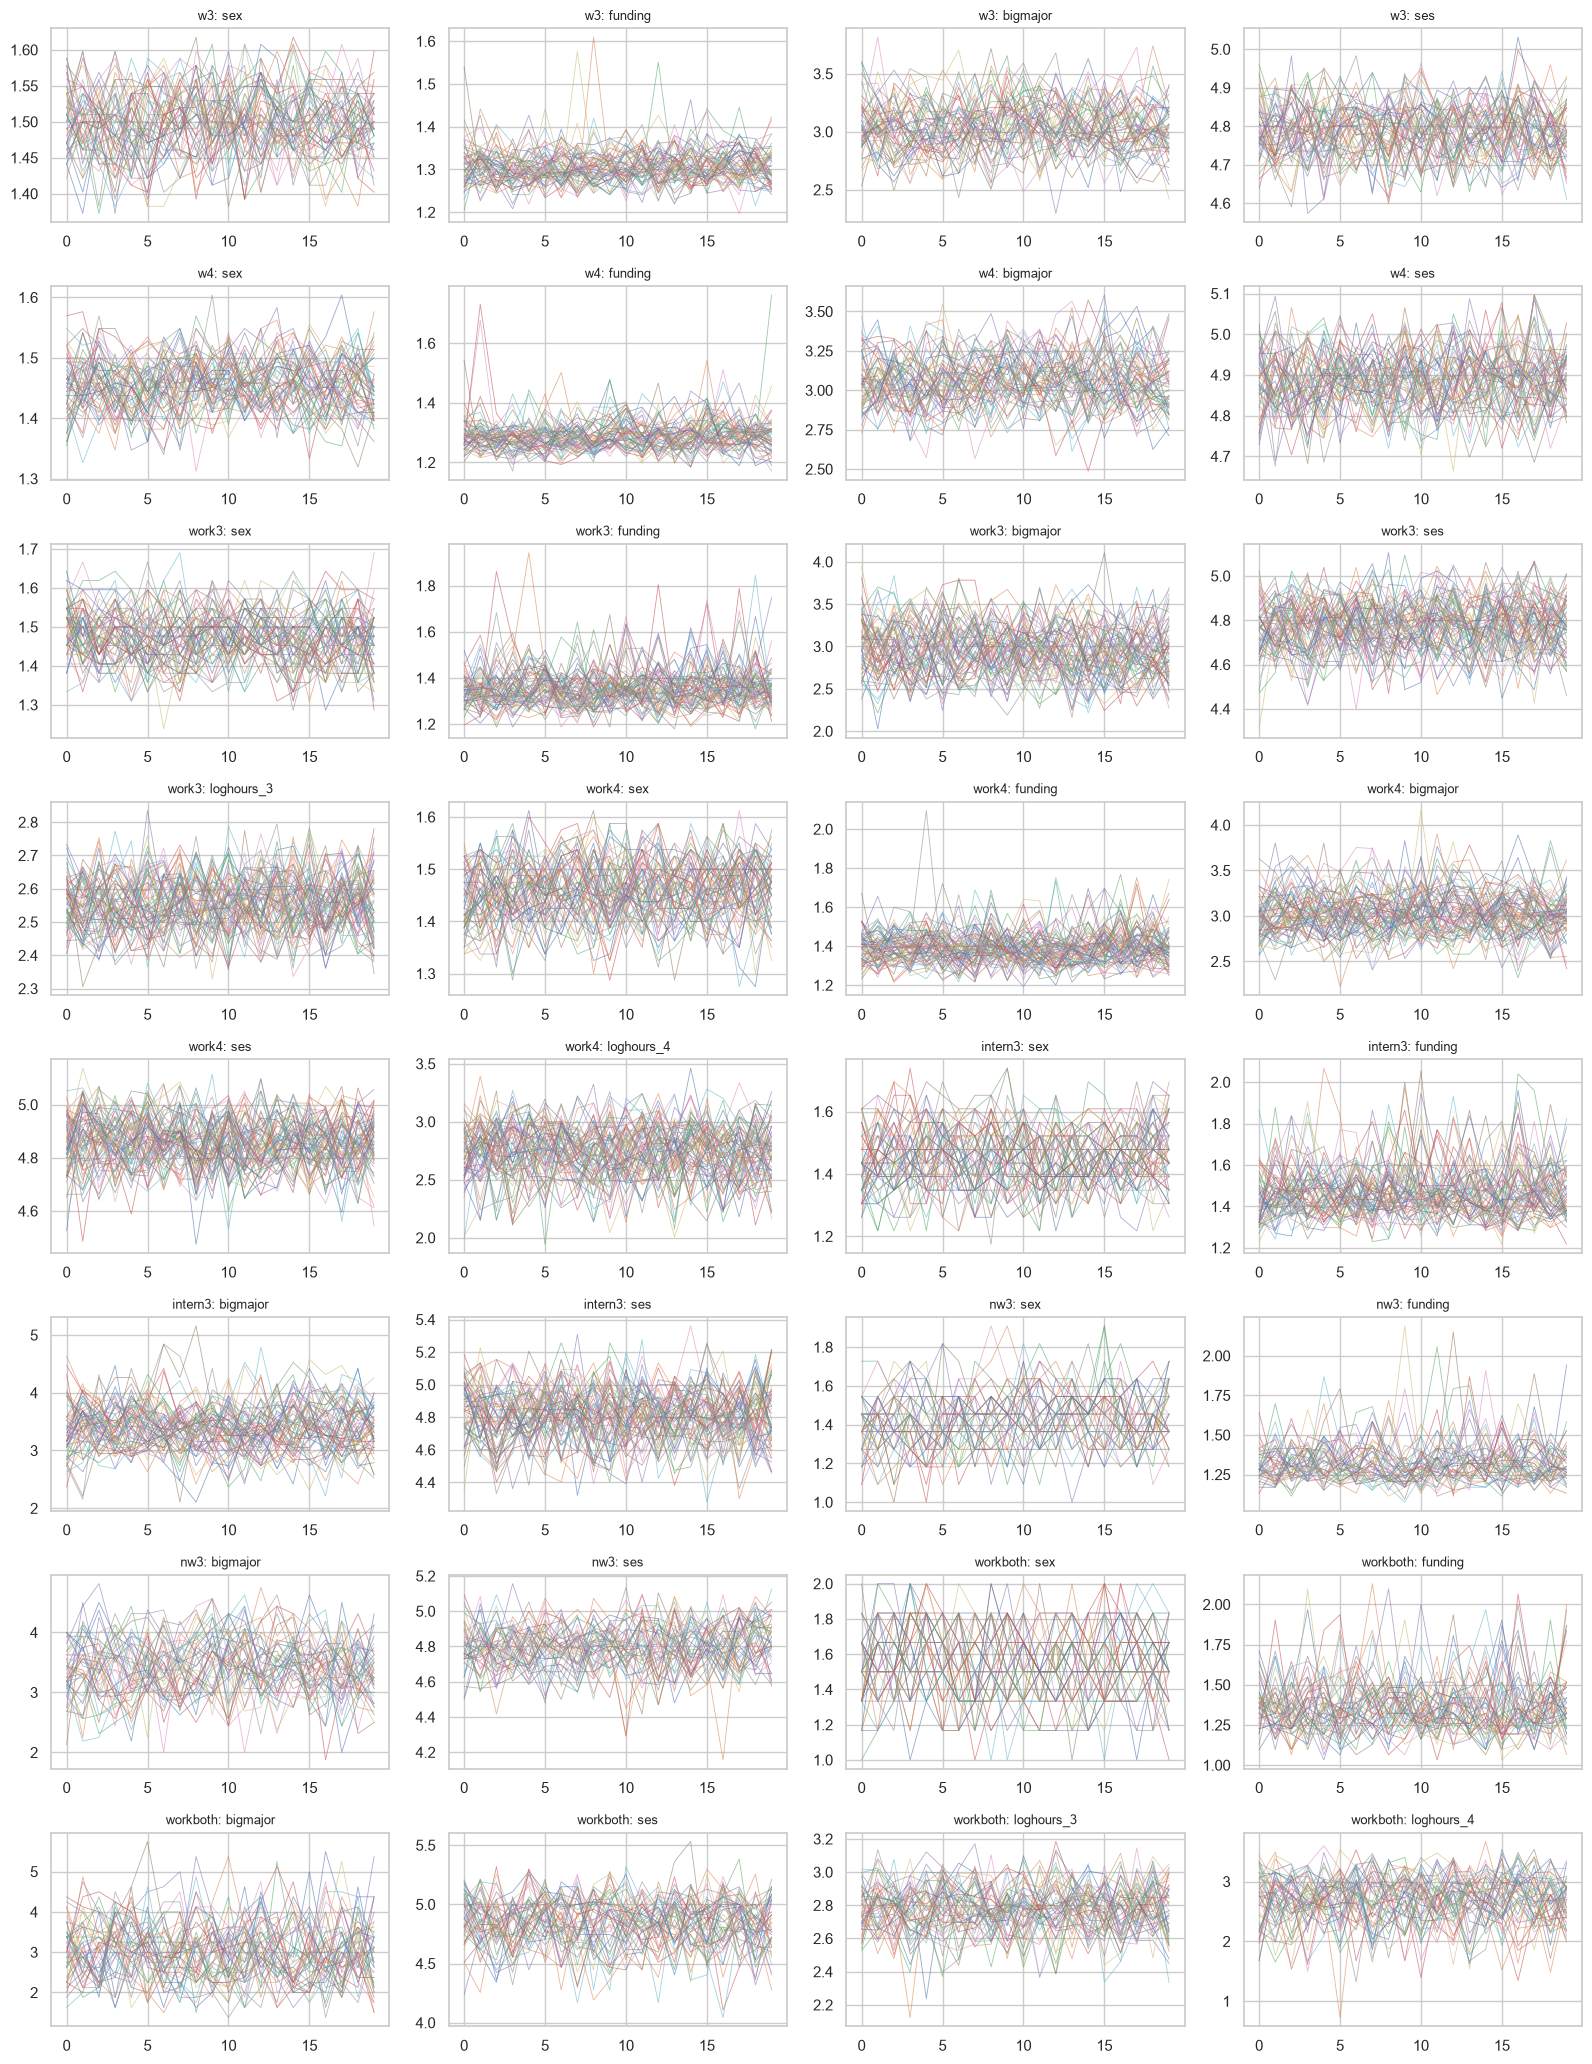

In [42]:
# Сходимость: средние восстановленных значений по итерациям, одна линия — один набор
panels = [(name, var) for name, trace in TRACES.items() for var in trace
          if keep_imputed(MICE_INPUT[name][0])[var].any()]
n_cols = 4
fig, axes = plt.subplots(int(np.ceil(len(panels) / n_cols)), n_cols, figsize=(16, 2.6 * np.ceil(len(panels) / n_cols)),
                         squeeze=False)
for ax, (name, var) in zip(axes.flat, panels):
    ax.plot(TRACES[name][var].T, lw=0.6, alpha=0.6)
    ax.set_title(f'{name}: {var}', fontsize=9)
for ax in axes.flat[len(panels):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Вывод.** Линии перемешаны и не имеют тренда — восстановление сошлось.

Сравниваем наблюдённые и восстановленные значения.

In [43]:
# Наблюдённые и восстановленные значения (при MAR не обязаны совпадать)
comparison = []
for name, long in IMPUTED.items():
    frame = MICE_INPUT[name][0]
    keep = keep_imputed(frame)
    imputed = long[long['.imp'] > 0].set_index('row')
    for var in keep.columns[keep.any()]:
        observed = frame[var].dropna()
        filled = imputed.loc[imputed.index.isin(keep.index[keep[var]]), var]
        if var.startswith('loghours'):
            observed, filled = np.expm1(observed), np.expm1(filled)
            row = {'наблюдено': f'медиана {observed.median():.0f} (IQR {observed.quantile(.25):.0f}–{observed.quantile(.75):.0f})',
                   'восстановлено': f'медиана {filled.median():.0f} (IQR {filled.quantile(.25):.0f}–{filled.quantile(.75):.0f})'}
        else:
            row = {'наблюдено': observed.value_counts(normalize=True).sort_index().round(2).to_dict(),
                   'восстановлено': filled.value_counts(normalize=True).sort_index().round(2).to_dict()}
        comparison.append({'набор': name, 'переменная': var, 'n восстановленных': keep[var].sum(), **row})
pd.DataFrame(comparison).set_index(['набор', 'переменная'])

n восстановленных  \
набор    переменная                      
w3       sex                       102   
         funding                   274   
         bigmajor                   81   
         ses                       415   
w4       sex                       144   
         funding                   223   
         bigmajor                  152   
         ses                       321   
work3    sex                        42   
         funding                   123   
         bigmajor                   37   
         ses                       181   
         loghours_3                 79   
work4    sex                        80   
         funding                   125   
         bigmajor                   81   
         ses                       175   
         loghours_4                 13   
intern3  sex                        23   
         funding                    74   
         bigmajor                   19   
         ses                        97   
nw3      sex                        11   
         funding                    53   
         bigmajor                   16   
         ses                        96   
workboth sex                         6   
         funding                    31   
         bigmajor                    8   
         ses                        47   
         loghours_3                 21   
         loghours_4                  6   

                                                                              наблюдено  \
набор    переменная                                                                       
w3       sex                                                     {1.0: 0.57, 2.0: 0.43}   
         funding                                      {1.0: 0.79, 2.0: 0.16, 3.0: 0.04}   
         bigmajor                          {1.0: 0.16, 2.0: 0.55, 5.0: 0.14, 7.0: 0.15}   
         ses         {1.0: 0.02, 2.0: 0.04, 3.0: 0.05, 4.0: 0.15, 5.0: 0.46, 6.0: 0.27}   
w4       sex                                                     {1.0: 0.54, 2.0: 0.46}   
         funding                                      {1.0: 0.78, 2.0: 0.19, 3.0: 0.02}   
         bigmajor                          {1.0: 0.15, 2.0: 0.53, 5.0: 0.18, 7.0: 0.13}   
         ses         {1.0: 0.01, 2.0: 0.03, 3.0: 0.06, 4.0: 0.17, 5.0: 0.45, 6.0: 0.28}   
work3    sex                                                     {1.0: 0.56, 2.0: 0.44}   
         funding                                      {1.0: 0.77, 2.0: 0.18, 3.0: 0.05}   
         bigmajor                          {1.0: 0.16, 2.0: 0.51, 5.0: 0.15, 7.0: 0.18}   
         ses          {1.0: 0.03, 2.0: 0.05, 3.0: 0.06, 4.0: 0.14, 5.0: 0.42, 6.0: 0.3}   
         loghours_3                                               медиана 15 (IQR 8–25)   
work4    sex                                                     {1.0: 0.57, 2.0: 0.43}   
         funding                                      {1.0: 0.78, 2.0: 0.19, 3.0: 0.04}   
         bigmajor                          {1.0: 0.13, 2.0: 0.56, 5.0: 0.19, 7.0: 0.11}   
         ses          {1.0: 0.0, 2.0: 0.03, 3.0: 0.05, 4.0: 0.17, 5.0: 0.45, 6.0: 0.29}   
         loghours_4                                               медиана 16 (IQR 7–26)   
intern3  sex                                                     {1.0: 0.62, 2.0: 0.38}   
         funding                                       {1.0: 0.75, 2.0: 0.2, 3.0: 0.04}   
         bigmajor                           {1.0: 0.16, 2.0: 0.53, 5.0: 0.2, 7.0: 0.11}   
         ses         {1.0: 0.03, 2.0: 0.05, 3.0: 0.06, 4.0: 0.12, 5.0: 0.41, 6.0: 0.33}   
nw3      sex                                                     {1.0: 0.55, 2.0: 0.45}   
         funding                                      {1.0: 0.82, 2.0: 0.16, 3.0: 0.02}   
         bigmajor                          {1.0: 0.16, 2.0: 0.57, 5.0: 0.16, 7.0: 0.11}   
         ses          {1.0: 0.01, 2.0: 0.04, 3.0: 0.04, 4.0: 0.17, 5.0: 0.5, 6.0: 0.25}   
workboth sex                                

**Вывод.** Распределения социальных характеристик близки. Восстановленные часы отличаются от наблюдённых (3-я волна: медиана 12 против 15; 4-я: 20 против 16). При MAR это допустимо: пропуски чаще у людей с другими характеристиками.

## 16. Флаги качества

Схема по аналогии с Delft-FEWS (Deltares): код качества = происхождение × надёжность, плюс коды причин. Для каждой аналитической переменной — `q_<имя>` и `qsrc_<имя>`.

| Код | Происхождение / надёжность | Использование |
|---|---|---|
| 0 | исходное / надёжное | основной анализ |
| 1 | исправленное / надёжное | основной анализ |
| 2 | восстановленное / надёжное | основной анализ (восстановленные наборы) |
| 3–5 | то же / сомнительное | основной анализ + проверка устойчивости без них |
| 6 | исходное / ненадёжное | не используется |
| 9 | пропуск | не используется |
| 99 | не применимо | — |

| Причина | Описание | Надёжность |
|---|---|---|
| `HL` | выход за логические границы | ненадёжное |
| `SL` | выход за статистические границы | сомнительное |
| `CENS` | крайний вариант шкалы сна | сомнительное |
| `ZERO` | 0 рабочих часов у работающего | сомнительное |
| `CONS` | противоречие с другим ответом той же волны | сомнительное |
| `WAVE` | противоречие между волнами | сомнительное |
| `SR` | повторяющийся профиль или совпадение строк | сомнительное |
| `PART` | частично заполненная анкета 4-й волны | сомнительное |
| `WFC` | признак волны расходится с ответами | сомнительное |
| `TXT` | значение из текстовой сводки | не меняет |
| `MAN` | ручное кодирование открытого ответа | исправленное |
| `IMP` | восстановлено | восстановленное |

Специальные ответы — исходные надёжные (код 0); их тип хранится в статусе.

Присваиваем флаги качества каждой аналитической переменной.

In [44]:
Q_LABELS = {0: 'исходное, надёжное', 1: 'исправленное, надёжное', 2: 'восстановленное, надёжное',
            3: 'исходное, сомнительное', 4: 'исправленное, сомнительное', 5: 'восстановленное, сомнительное',
            6: 'исходное, ненадёжное', 9: 'пропуск', 99: 'не применимо'}
DOUBTFUL = {'SL', 'CENS', 'ZERO', 'CONS', 'WAVE', 'SR', 'PART', 'WFC'}
STATUS_TO_QUALITY = {'VALID': 0, 'DK': 0, 'REF': 0, 'OTHER': 0, 'ROUTING_ERR': 99, 'INVALID': 6,
                     'MISS': 9, 'NOT_REACHED': 9, 'NA_SKIP': 99, 'NOT_IN_WAVE': 99}
STATUS_PRIORITY = ['NOT_IN_WAVE', 'NA_SKIP', 'NOT_REACHED', 'MISS', 'INVALID', 'ROUTING_ERR', 'OTHER', 'REF', 'DK', 'VALID']
NO_FLAG = pd.Series(False, index=d.index)


def flag(col):
    return d[col].fillna(False).astype(bool)


def worst_status(items):
    '''Наихудший статус среди исходных вопросов составной переменной.'''
    rank = pd.concat([d[f'{item}_st'].map({s: i for i, s in enumerate(STATUS_PRIORITY)}) for item in items], axis=1)
    return rank.min(axis=1).map(dict(enumerate(STATUS_PRIORITY)))


def imputed_cells(var):
    '''Строки, где значение восстановлено хотя бы в одном наборе.'''
    rows = set()
    for frame, _ in MICE_INPUT.values():
        if var in frame:
            keep = keep_imputed(frame)[var]
            rows |= set(keep.index[keep])
    return d.index.isin(list(rows))


ROW_REASONS = {'3': {'SR': flag('dup_flag'), 'WFC': flag('wave_flag_conflict')},
               '4': {'SR': flag('dup_flag') | flag('tech_4w'), 'PART': flag('partial_4w'),
                     'WFC': flag('wave_flag_conflict')}}


def hours_reasons(w):
    return {'SL': flag(f'hours_{w}_modz') | flag(f'hours_{w}_tukey'),
            'CONS': flag(f'hours_{w}_inconsistent'), 'ZERO': flag(f'hours_{w}_zero')}


def sleep_reasons(day, w):
    return {'HL': flag(f'sleep_{day}_{w}_invalid'),
            'SL': flag(f'sleep_{day}_{w}_short') | flag(f'sleep_{day}_{w}_long'),
            'CENS': flag(f'sleep_{day}_{w}_censored')}


# имя: (волна, исходные вопросы, причины, признак ручного перекодирования, переменная восстановления)
QUALITY_VARS = {}
for w in ['3', '4']:
    sleep = SLEEP_ITEMS[w]
    recoded_motive = (d['motive_rec_4'].astype(str) != d['motive_raw_4'].astype(str)) & d['motive_raw_4'].notna()
    recoded_sphere = (d['sphere_rec_4'].astype(str) != d['sphere_4'].astype(str)) & d['sphere_4'].notna()
    QUALITY_VARS.update({
        f'fmt_{w}': (w, ['work1' if w == '3' else 'work1_4w'], {}, None, None),
        f'hours_{w}': (w, ['work_hours' if w == '3' else 'work_hours_4w'], hours_reasons(w), None, f'loghours_{w}'),
        f'mark_{w}': (w, [f'mark_{w}w'], {}, None, None),
        f'sat_{w}': (w, [f'satisfaction_{w}w'], {}, None, None),
        f'edu3_{w}': (w, [f'edu3_{w}w'], {}, None, None),
        f'drop_any_{w}': (w, [f'dropout1_{w}w'],
                          {'WAVE': d['drop_any_3'].eq(1) & d['drop_any_4'].eq(0)} if w == '4' else {}, None, None),
        f'reasons_{w}': (w, [f'reasons_{w}w_any'],
                         {'CONS': flag('reason_dk_conflict_4'),
                          'TXT': flag('reason_dk_4_txt') | flag('reason_other_4_txt')} if w == '4' else {}, None, None),
        f'motive_{w}': (w, ['work4' if w == '3' else 'work4_4w'],
                        {'CONS': flag('motive_open_conflict_4')} if w == '4' else {},
                        recoded_motive if w == '4' else None, None),
        f'sphere_{w}': (w, [f'work2_{w}w'], {'CONS': flag('sphere_open_conflict_4')} if w == '4' else {},
                        recoded_sphere if w == '4' else None, None),
        f'intern_{w}': (w, ['intern1' if w == '3' else 'intern1_4w'], {}, None, None),
        f'intern_paid_{w}': (w, ['intern3' if w == '3' else 'intern3_4w'], {}, None, None),
        f'intent_{w}': (w, ['work_intentions' if w == '3' else 'work_intentions_4w'], {}, None, None),
        f'pe_{w}': (w, ['pe_3w_1' if w == '3' else 'pe_4w'], {}, None, None),
        f'smoke_{w}': (w, [f'smoking_{w}w'], {}, None, None),
        f'alco_{w}': (w, [f'alco_{w}w'], {}, None, None),
        f'sleep_wd_{w}': (w, [sleep[0], sleep[2]], sleep_reasons('wd', w), None, None),
        f'sleep_we_{w}': (w, [sleep[1], sleep[3]], sleep_reasons('we', w), None, None),
        f'sjl_{w}': (w, list(sleep), {'HL': flag(f'sleep_wd_{w}_invalid') | flag(f'sleep_we_{w}_invalid'),
                                      'CENS': flag(f'sleep_wd_{w}_censored') | flag(f'sleep_we_{w}_censored')},
                     None, None),
    })
QUALITY_VARS.update({name: (name[-1], [item], {}, None, None) for name, item in {
    'intern_motive_3': 'intern4', 'intern_fit_3': 'intern5_1', 'intern_benefit_3': 'intern5_2',
    'intern_harm_3': 'intern5_3', 'intern_difficulty_3': 'intern5_4', 'pe_freq_3': 'pe_3w_2',
    'alloc_3': 'hours_3w_1', 'intern_fit_4': 'intern_major1_4w', 'fit_4': 'Work_major_4w',
    'benefit_4': 'intern5_4w_1', 'harm_4': 'intern5_4w_2', 'difficulty_4': 'intern5_4w_3'}.items()})


def set_quality(name, base, reasons, corrected=None, completed=None):
    '''Записывает код качества q_<name> и коды причин qsrc_<name>.'''
    quality = base.copy()
    if corrected is not None:
        quality[corrected.fillna(False) & quality.eq(0)] = 1
    if completed is not None:
        quality[completed & quality.isin([6, 9])] = 2
    doubtful = np.logical_or.reduce([mask.fillna(False) for code, mask in reasons.items() if code in DOUBTFUL]
                                    or [NO_FLAG])
    quality[doubtful & quality.isin([0, 1, 2])] += 3
    active = quality.ne(99)
    labels = pd.Series('', index=d.index)
    extra = {'MAN': corrected, 'IMP': completed}
    for code, mask in list(reasons.items()) + [(c, m) for c, m in extra.items() if m is not None]:
        labels[pd.Series(mask, index=d.index).fillna(False) & active] += code + '|'
    d[f'q_{name}'] = quality.astype(int)
    d[f'qsrc_{name}'] = labels.str.rstrip('|')


for name, (w, items, reasons, corrected, imputed_var) in QUALITY_VARS.items():
    status = worst_status(items)
    reasons = {**reasons, **ROW_REASONS[w]}
    reasons['HL'] = reasons.get('HL', NO_FLAG) | status.eq('INVALID')
    base = status.map(STATUS_TO_QUALITY)
    base[reasons['HL'] & base.eq(0)] = 6
    set_quality(name, base, reasons, corrected, imputed_cells(imputed_var) if imputed_var else None)

for var, imputed_var in [('sex', 'sex'), ('funding', 'funding'), ('bigmajor', 'bigmajor'), ('ses1', 'ses')]:
    base = pd.Series(np.where(d[var].notna(), 0, 9), index=d.index)
    base[~d['in_study']] = 99
    set_quality(var, base, {}, None, imputed_cells(imputed_var))

quality_cols = [c for c in d.columns if c.startswith('q_')]
quality_summary = (pd.DataFrame({c[2:]: d.loc[d['in_study'], c].value_counts() for c in quality_cols}).T
                   .reindex(columns=list(Q_LABELS)).fillna(0).astype(int).rename(columns=Q_LABELS))
quality_summary['причины'] = pd.Series({
    c[5:]: d.loc[d['in_study'], c].str.split('|').explode().replace('', np.nan).dropna().value_counts().to_dict()
    for c in d.columns if c.startswith('qsrc_')})
quality_summary

,"исходное, надёжное","исправленное, надёжное","восстановленное, надёжное","исходное, сомнительное","исправленное, сомнительное","восстановленное, сомнительное","исходное, ненадёжное",пропуск,не применимо,причины
fmt_3,1209,0,0,2,0,0,0,13,798,{'WFC': 2}
hours_3,429,0,79,25,0,0,0,13,1476,"{'IMP': 79, 'HL': 15, 'CONS': 15, 'SL': 14, 'WFC': 1}"
mark_3,1181,0,0,1,0,0,0,42,798,{'WFC': 2}
sat_3,1165,0,0,1,0,0,0,58,798,{'WFC': 2}
edu3_3,1221,0,0,2,0,0,0,1,798,{'WFC': 2}
drop_any_3,1221,0,0,2,0,0,0,1,798,{'WFC': 2}
reasons_3,461,0,0,1,0,0,0,70,1490,{'WFC': 2}
motive_3,532,0,0,1,0,0,0,13,1476,{'WFC': 1}
sphere_3,428,0,0,1,0,0,0,117,1476,{'WFC': 1}
intern_3,1209,0,0,2,0,0,0,13,798,{'WFC': 2}


**Вывод.** Большинство значений — исходные надёжные (код 0). Сомнительные (коды 3–5) сосредоточены в часах, сне и 4-й волне (частичные анкеты).

Функция `usable()` выбирает значения для основного анализа или проверки устойчивости; таблица показывает, сколько наблюдений теряется без сомнительных значений.

In [45]:
def usable(name, robust=False):
    '''Значения для анализа: коды 0–5 (основной) или 0–2 (проверка устойчивости).'''
    return d[f'q_{name}'].isin([0, 1, 2] if robust else [0, 1, 2, 3, 4, 5])


QUALITY_ALIAS = {'funding_c': 'funding', 'ses': 'ses1', 'sex_c': 'sex', 'major_c': 'bigmajor'}
PREFIX_ALIAS = [('sleep_dur_wd', 'sleep_wd'), ('sleep_dur_we', 'sleep_we'), ('reason', 'reasons'),
                ('intern_motive', 'intern_motive'), ('motive', 'motive'), ('pay_tuition', 'motive'),
                ('alloc', 'alloc'), ('plan_work', 'alloc'), ('sphere', 'sphere')]


def quality_name(var):
    '''Имя переменной с флагом качества для аналитической переменной.'''
    if f'q_{var}' in d:
        return var
    if var in QUALITY_ALIAS:
        return QUALITY_ALIAS[var]
    for prefix, target in PREFIX_ALIAS:
        if var.startswith(prefix) and f'q_{target}_{var[-1]}' in d:
            return f'{target}_{var[-1]}'
    return None


robust_rows = []
for name, (mask, required, extra) in SAMPLES.items():
    flagged = sorted({quality_name(v) for v in required + extra} - {None})
    if not flagged:
        continue
    main = mask & d[required].notna().all(axis=1)
    robust = main & np.logical_and.reduce([usable(v, robust=True) for v in flagged])
    robust_rows.append({'проверка': name, 'основной анализ': main.sum(), 'без сомнительных': robust.sum(),
                        'исключается': main.sum() - robust.sum(), 'переменные с флагами': ', '.join(flagged)})
robust_sizes = pd.DataFrame(robust_rows).set_index('проверка')
robust_sizes

,основной анализ,без сомнительных,исключается,переменные с флагами
проверка,,,,
"З1.1, 3 в.",1211,1209,2,fmt_3
"Г1.2, 3 в.",897,897,0,funding
"Г1.3, 3 в.",793,793,0,ses1
"Г1.4, 3 в.",342,342,0,"motive_3, ses1"
"З1.5, 3 в.",410,409,1,"funding, motive_3"
"З1.6, 3 в.",429,428,1,sphere_3
"Г2.1, 3 в.",444,420,24,"hours_3, mark_3"
"Г2.2, 3 в.",432,409,23,"hours_3, sat_3"
"Г2.3, 3 в.",727,726,1,"drop_any_3, fmt_3"


**Вывод.** Для большинства гипотез потери малы (0–2%). Сильнее всего сокращаются выборки с часами и сном 4-й волны: Г2.1 — с 412 до 336, Г5.2 — с 423 до 325.

## 17. Протокол очистки

Наблюдение → правило → затронуто → последствия для анализа. Предполагаемая причина записана отдельно и не является установленным фактом.

Сводный протокол: что обнаружено, какое правило применено и сколько записей затронуто.

In [46]:
def count(mask):
    return int(np.asarray(mask).sum())


last_items_blank = sum(count(d[pe].notna() & d[f'{item}_st'].eq('NOT_REACHED'))
                       for pe, item in [('pe_3w_1', 'smoking_3w'), ('pe_3w_1', 'alco_3w'),
                                        ('pe_4w', 'smoking_4w'), ('pe_4w', 'alco_4w')])
LOG = [
    ('Нет ответов на исследуемые вопросы', 'исключаются из рабочего массива', count(~d['in_study']),
     'не входят ни в один анализ', 'незавершённые или пустые анкеты'),
    ('Признак волны расходится с ответами', 'участие по ответам; флаг WFC', count(d['wave_flag_conflict']),
     'запись входит в анализ той волны, где есть ответы', 'неизвестна'),
    ('Полное совпадение строк (≥ 15 ответов)', 'сохраняются; флаг SR', count(d['dup_flag']),
     'входят во все анализы', 'повторная отправка или совпадение — различить нельзя'),
    ('4-я волна: нет ответа о работе', 'сохраняются; флаг PART', count(d['partial_4w']),
     'не входят в анализы с работой; З2.5 — с ними и без них', 'не установлена'),
    ('Сфера 3-й волны в трёх столбцах', 'объединение; проверка соответствия формату', count(d['work2_3w'].notna()),
     'одна переменная сферы', 'структура выгрузки'),
    ('«Затрудняюсь» и «другое» в причинах — только в сводке', 'разбор текстовой сводки; код TXT',
     count(d['reason_dk_4_txt'] | d['reason_other_4_txt']), 'статус DK / признак «другое»', 'структура выгрузки'),
    ('«Затрудняюсь» вместе с причиной', 'флаг CONS; причины сохраняются', count(d['reason_dk_conflict_4']),
     'проверка устойчивости', '—'),
    ('Расшифровки «другого» в причинах нет', 'вариант учитывается без содержания', count(d['reason_other_4_txt']),
     'причина «другое» не детализируется', 'поле не передано'),
    ('dropout1_3w = 3: причины не спрашивались', 'NA_SKIP', count(d['dropout1_3w'].eq(3)),
     'основание причин 3-й волны — код 2', 'маршрут анкеты'),
    ('Рабочие часы < 0 или > 168', 'INVALID; флаг HL; восстанавливаются',
     count(d['work_hours_st'].eq('INVALID')) + count(d['work_hours_4w_st'].eq('INVALID')),
     'в моделях после восстановления', '—'),
    ('0 часов у работающего', 'флаг ZERO', count(d['hours_3_zero']) + count(d['hours_4_zero']),
     'проверка устойчивости', '—'),
    ('Ночной интервал ≤ 0', 'флаг HL; не восстанавливается',
     sum(count(d[f'sleep_{day}_{w}_invalid']) for day in ['wd', 'we'] for w in ['3', '4']),
     'не входят в анализ сна', 'ошибка ответа'),
    ('Курение и алкоголь 3-й волны: пустые ответы', 'сохраняются как пропуски неизвестного происхождения',
     count(d.loc[d['in_w3'], ['smoking_3w_st', 'alco_3w_st']].isin(['MISS', 'NOT_REACHED']).sum().sum()),
     'основные сравнения — «да»/«нет»', 'возможна потеря кода отказа — не подтверждено'),
    ('Пустой ответ на последние вопросы анкеты', 'NOT_REACHED по правилу', last_items_blank,
     'пропуск вопроса и прерывание анкеты не различимы', '—'),
    ('Распределение времени: все доли 0', 'пропуск', count(d['hours_3w_1_st'].eq('MISS')), 'не входят в З6.1, Г6.3, З6.4', '—'),
    ('Распределение времени: нулевые доли', 'сохраняются', count((d[ALLOC_COLS] == 0).any(axis=1)),
     'для работы — наличие доли > 0 и её величина', '—'),
    ('Открытые ответы о мотиве', 'перенос только при однозначном соответствии; флаг MAN',
     count(d['work4_4w_88'].notna()), 'основной анализ — исходные категории', '—'),
    ('Открытые ответы о сфере', 'перенос при однозначном соответствии; иначе описательный код',
     count(d['work2_4w_88'].notna()), 'З1.1, З1.6', '—'),
    ('«Не работаю» в открытом ответе работающего', 'флаг CONS',
     count(d['motive_open_conflict_4'] | d['sphere_open_conflict_4']), 'ответ о работе сохраняется', '—'),
    ('«Думал» об отчислении в 3-й волне, «не думал» в 4-й', 'флаг WAVE',
     count(d['drop_any_3'].eq(1) & d['drop_any_4'].eq(0)), 'ограничение для З7.6', 'противоречие ответов'),
    ('Пустые социальные характеристики', 'восстанавливаются; флаг IMP',
     count(d.loc[d['in_study'], ['sex', 'funding', 'bigmajor', 'ses1']].isna().sum().sum()),
     'сравнение с полными случаями', 'пропуск зависит от направления и пола'),
    ('bigmajor = 4 или 8', 'исключаются из моделей с поправкой на направление',
     count(d.loc[d['in_study'], 'bigmajor'].isin([4, 8])), 'описываются отдельно', '—'),
]
cleaning_log = pd.DataFrame(LOG, columns=['наблюдение', 'правило', 'затронуто', 'последствия', 'предполагаемая причина'])
cleaning_log

,наблюдение,правило,затронуто,последствия,предполагаемая причина
0,Нет ответов на исследуемые вопросы,исключаются из рабочего массива,3809,не входят ни в один анализ,незавершённые или пустые анкеты
1,Признак волны расходится с ответами,участие по ответам; флаг WFC,18,"запись входит в анализ той волны, где есть ответы",неизвестна
2,Полное совпадение строк (≥ 15 ответов),сохраняются; флаг SR,8,входят во все анализы,повторная отправка или совпадение — различить нельзя
3,4-я волна: нет ответа о работе,сохраняются; флаг PART,599,не входят в анализы с работой; З2.5 — с ними и без них,не установлена
4,Сфера 3-й волны в трёх столбцах,объединение; проверка соответствия формату,429,одна переменная сферы,структура выгрузки
5,«Затрудняюсь» и «другое» в причинах — только в сводке,разбор текстовой сводки; код TXT,68,статус DK / признак «другое»,структура выгрузки
6,«Затрудняюсь» вместе с причиной,флаг CONS; причины сохраняются,12,проверка устойчивости,—
7,Расшифровки «другого» в причинах нет,вариант учитывается без содержания,25,причина «другое» не детализируется,поле не передано
8,dropout1_3w = 3: причины не спрашивались,NA_SKIP,15,основание причин 3-й волны — код 2,маршрут анкеты
9,Рабочие часы < 0 или > 168,INVALID; флаг HL; восстанавливаются,27,в моделях после восстановления,—


**Вывод.** Протокол — основа раздела о подготовке данных в статье (`methods.md`).

## 18. Сохранение

- `data_clean.pkl` — исходные переменные, статусы, аналитические переменные и флаги качества;
- `data_imputed.pkl` — восстановленные наборы по семействам моделей (длинный формат, `.imp` = 0 — исходные данные).

Оба файла загружаются в `analysis.ipynb`.

In [47]:
d.to_pickle('data_clean.pkl')
pd.to_pickle(IMPUTED, 'data_imputed.pkl')
print(f'data_clean.pkl: {d.shape[0]} строк, {d.shape[1] - df.shape[1]} новых переменных; '
      f'data_imputed.pkl: {len(IMPUTED)} наборов')

data_clean.pkl: 5831 строк, 316 новых переменных; data_imputed.pkl: 7 наборов


**Готово.** Очищенные данные сохранены. Анализ продолжается в `analysis.ipynb`.